In [1]:
from tqdm import tqdm
import torch
from functools import partial

In [2]:
import pandas as pd

In [3]:
import networkx as nx

In [4]:
import matplotlib.pyplot as plt

In [5]:
fol_base_path = "C:\\FOLBench\\FOL-GemmaOutput\\"

In [6]:
from metrics import (
 
 predicate_argument_alignment_score,
 quantifier_scope_similarity,
 variable_binding_consistency,
 equivalence_score,
 ted_structural_similarity,
predicate_alignment_hungarian_similarity,

 folbench_score,
)
from metrics.utils import (build_graph)

In [7]:
from metrics import visualize_fol_graph

### TEST

In [320]:
def parse_fol_to_graph(fol_str: str) -> nx.DiGraph:
    """
    Convert a FOL string into a FOLBench graph.
    Replace this with your actual parser.
    """
    g = nx.DiGraph()
    # Minimal placeholder: one predicate node
    g.add_node("root", type="predicate", label=fol_str, is_root=True)
    return g

In [8]:
f = fol_base_path + "//FOL_answers_Exp3_TP_0Shot.tsv"
phi = pd.read_csv(f,sep='\t')

In [9]:
phi.head()

,index,NL,FOL,LLM_Response
0,0,A vacation is relaxing if it includes beautifu...,∀x (Vacation(x) ∧ Relaxing(x) → (BeautifulScen...,∀x (Vacation(x) ∧ BeautifulScenery(x) ∧ Enjoya...
1,1,"A gemstone can be a diamond, a ruby, or an eme...",∀x (Gemstone(x) → ((Diamond(x) ∧ ¬(Ruby(x) ∨ E...,∀x (Gemstone(x) → ((Diamond(x) ⊕ Ruby(x) ⊕ Eme...
2,2,People who speak more than one language are bi...,∀x (SpeakMultipleLanguages(x) → (Bilingual(x) ...,∀x (Person(x) ∧ SpeaksMoreThanOneLanguage(x) →...
3,3,An organization is non-profit if it has a char...,∀x (Organization(x) ∧ CharitableMission(x) ∧ ¬...,∀x (Organization(x) ∧ CharitableMission(x) ∧ ¬...
4,4,A flower is characterized as a monocot if it h...,∀x (Flower(x) ∧ SingleCotyledon(x) ∧ ParallelV...,∀x (Flower(x) ∧ SingleCottiledon(x) ∧ Parallel...


In [10]:
phi['FOL'].values[994],phi['LLM_Response'].values[994]

('∀x (Device(x) → ((On(x) ⊕ Off(x))))', '∀x (Device(x) → (On(x) ⊕ Off(x)))')

In [11]:
g1= build_graph(phi['LLM_Response'].values[994])

In [12]:
g1.nodes(data=True)

NodeDataView({'n1': {'type': 'quantifier', 'label': 'forall', 'is_root': True}, 'n2': {'type': 'variable', 'label': 'x'}, 'n3': {'type': 'connective', 'label': 'implies'}, 'n4': {'type': 'predicate', 'label': 'Device'}, 'n5': {'type': 'variable', 'label': 'x'}, 'n6': {'type': 'connective', 'label': 'xor'}, 'n7': {'type': 'predicate', 'label': 'On'}, 'n8': {'type': 'variable', 'label': 'x'}, 'n9': {'type': 'predicate', 'label': 'Off'}, 'n10': {'type': 'variable', 'label': 'x'}})

In [13]:
g1 = nx.DiGraph()
g2 = nx.DiGraph()
g1 = build_graph(phi['LLM_Response'].values[994])
g2 = build_graph(phi['FOL'].values[994])

In [14]:
folbench_score(g1,g2)

1.2

In [33]:
gp = parse_text_FOL_to_tree(phi['LLM_Response'].values[994])

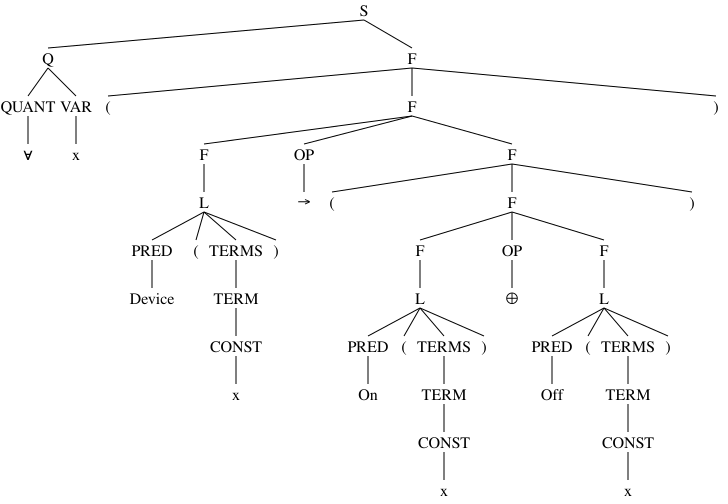

In [43]:
parse_text_FOL_to_tree(phi['LLM_Response'].values[994])

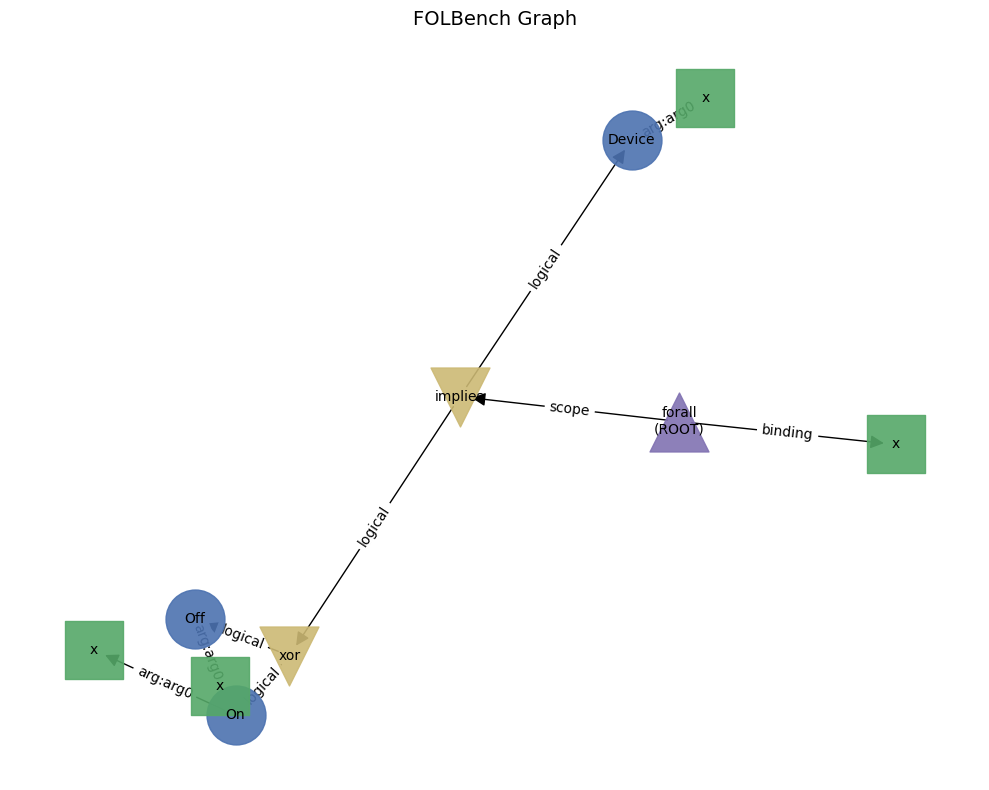

In [15]:
visualize_fol_graph(g1)

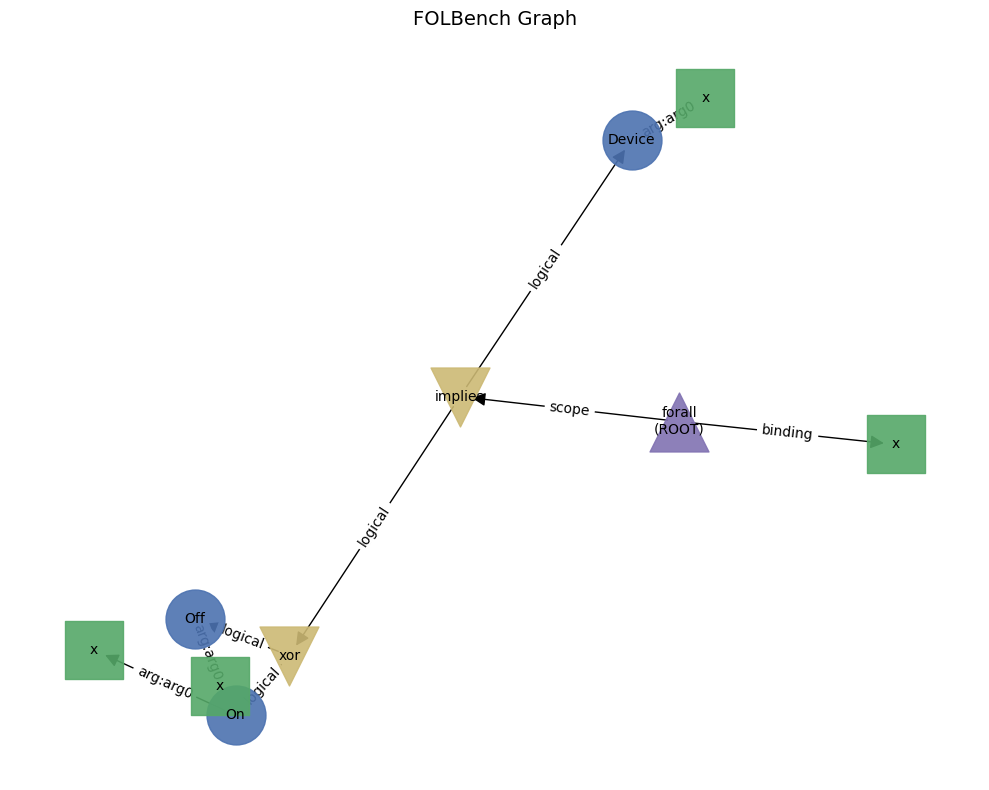

In [16]:
visualize_fol_graph(g2)

In [36]:
def logicllama_tree_to_folbench_graph(t: Tree) -> nx.DiGraph:
     """
     Convert a LogicLLaMA-style NLTK syntax tree into a FOLBench semantic graph.
     """

     g = nx.DiGraph()
     node_counter = [0]
    
     def new_id():
         node_counter[0] += 1
         return f"n{node_counter[0]}"
    
     def add_node(node_id, ntype, label, is_root=False):
         g.add_node(node_id,
         type=ntype,
         label=label,
         is_root=is_root)
    
     def process(tree, parent=None, edge_type=None, role=None):
         """
         Recursively convert NLTK Tree → FOLBench graph.
         """
        
         # Leaf variable or constant
         if isinstance(tree, str):
             nid = new_id()
             add_node(nid, "variable", tree)
             if parent:
                 g.add_edge(parent, nid, type=edge_type, role=role)
             return nid
    
         label = tree.label()
    
         # Quantifier node
         if label in ("forall", "exists"):
             nid = new_id()
             add_node(nid, "quantifier", label)
            
             # First child = bound variable
             var = tree[0]
             var_id = process(var)
             g.add_edge(nid, var_id, type="binding")
            
             # Second child = scope
             scope = tree[1]
             scope_id = process(scope, parent=nid, edge_type="scope")
        
             if parent:
                 g.add_edge(parent, nid, type=edge_type, role=role)
        
             return nid
    
         # Logical connectives
         if label in ("and", "or", "not", "implies"):
             nid = new_id()
             add_node(nid, "connective", label)
            
             for i, child in enumerate(tree):
                 child_id = process(child, parent=nid, edge_type="logical")
             if parent:
                 g.add_edge(parent, nid, type=edge_type, role=role)
             return nid
    
         # Predicate node
         nid = new_id()
         add_node(nid, "predicate", label)
        
         # Children are arguments
         for i, arg in enumerate(tree):
             arg_id = process(arg)
             g.add_edge(nid, arg_id, type="arg", role=f"arg{i}")
        
         if parent:
             g.add_edge(parent, nid, type=edge_type, role=role)
        
         return nid
    
     # Build graph
     root_id = process(t)
     g.nodes[root_id]["is_root"] = True
    
     return g

In [46]:
def visualize_folbench_graph(
 g: nx.DiGraph,
 title="FOLBench Graph",
 figsize=(12, 8),
 node_size=1800,
 font_size=10
):
     """
     Visualize a FOLBench semantic graph with:
     - Typed nodes (predicate, variable, quantifier, connective, constant)
     - Typed edges (arg, binding, scope, logical)
     - Edge labels (role for arg edges)
     - Root node highlighted
     """
    
     # Color scheme by node type
     type_to_color = {
     "predicate": "#4C72B0",
     "variable": "#55A868",
     "quantifier": "#8172B2",
     "connective": "#CCB974",
     "constant": "#C44E52",
     }
    
     # Shape scheme by node type
     type_to_shape = {
     "predicate": "o",
     "variable": "s",
     "quantifier": "D",
     "connective": "^",
     "constant": "v",
     }
    
     # Layout
     pos = nx.spring_layout(g, seed=42)
    
     plt.figure(figsize=figsize)
     plt.title(title, fontsize=14)
    
     # Draw nodes by type
     for ntype, color in type_to_color.items():
         nodes = [n for n, d in g.nodes(data=True) if d.get("type") == ntype]
         if nodes:
             nx.draw_networkx_nodes(
                 g,
                 pos,
                 nodelist=nodes,
                 node_color=color,
                 node_shape=type_to_shape[ntype],
                 node_size=node_size,
                 alpha=0.9,
             )
    
     # Node labels
     node_labels = {}
     for n, d in g.nodes(data=True):
         label = d.get("label", "")
         if d.get("is_root"):
             label += "\n(ROOT)"
         node_labels[n] = label
    
     nx.draw_networkx_labels(g, pos, labels=node_labels, font_size=font_size)
    
     # Edge labels
     edge_labels = {}
     for u, v, d in g.edges(data=True):
         etype = d.get("type")
         if etype == "arg":
             edge_labels[(u, v)] = f"arg:{d.get('role')}"
         else:
             edge_labels[(u, v)] = etype
    
     nx.draw_networkx_edges(
         g,
         pos,
         arrows=True,
         arrowstyle="-|>",
         arrowsize=20,
         width=1.8
     )
    
     nx.draw_networkx_edge_labels(
         g,
         pos,
         edge_labels=edge_labels,
         font_size=font_size
     )
    
     plt.axis("off")
     plt.tight_layout()
     plt.show()

In [38]:
gconv = logicllama_tree_to_folbench_graph(gp)

In [41]:
print(gconv.nodes(data=True))
print(gconv.edges(data=True))

[('n1', {'type': 'predicate', 'label': 'S', 'is_root': True}), ('n2', {'type': 'predicate', 'label': 'Q', 'is_root': False}), ('n3', {'type': 'predicate', 'label': 'QUANT', 'is_root': False}), ('n4', {'type': 'variable', 'label': '∀', 'is_root': False}), ('n5', {'type': 'predicate', 'label': 'VAR', 'is_root': False}), ('n6', {'type': 'variable', 'label': 'x', 'is_root': False}), ('n7', {'type': 'predicate', 'label': 'F', 'is_root': False}), ('n8', {'type': 'variable', 'label': '(', 'is_root': False}), ('n9', {'type': 'predicate', 'label': 'F', 'is_root': False}), ('n10', {'type': 'predicate', 'label': 'F', 'is_root': False}), ('n11', {'type': 'predicate', 'label': 'L', 'is_root': False}), ('n12', {'type': 'predicate', 'label': 'PRED', 'is_root': False}), ('n13', {'type': 'variable', 'label': 'Device', 'is_root': False}), ('n14', {'type': 'variable', 'label': '(', 'is_root': False}), ('n15', {'type': 'predicate', 'label': 'TERMS', 'is_root': False}), ('n16', {'type': 'predicate', 'label

In [26]:
folbench_score(g1,g2)

0.7999999999999999

In [21]:
rows = []
skip_count = 0
for i in range(phi.shape[0]):
    row = []
    g1 = nx.DiGraph()
    g2 = nx.DiGraph()
    try:
        g_pred = build_graph(phi['LLM_Response'].values[i])
        g_gold = build_graph(phi['FOL'].values[i])
        row.append(i)

        paas = predicate_argument_alignment_score(g_pred, g_gold)
        qss = quantifier_scope_similarity(g_pred, g_gold)
        vbc = variable_binding_consistency(g_pred, g_gold)
        cle = equivalence_score(g_pred, g_gold)
        ted = ted_structural_similarity(g_pred, g_gold)
        hungarian = predicate_alignment_hungarian_similarity(g_pred, g_gold)
        
        row.append(paas)
        row.append(qss)
        row.append(vbc)
        row.append(cle)
        row.append(ted)
        row.append(hungarian)
        
        #row.append(folbench_score(g_pred,g_gold))
        rows.append(row)
    except:
        pass
        skip_count +=1
        #print(i)
    
print("Skipped rows: " + str(skip_count))
#folscore = pd.DataFrame(rows,columns=['idx','folscore'])
folscore = pd.DataFrame(rows,columns=['idx','paas','qss','vbc','cle','ted','hungarian'])
folscore.describe()

Skipped rows: 56


,idx,paas,qss,vbc,cle,ted,hungarian
count,944.000000,944.000000,944.000000,944.000000,944.000000,944.000000,944.000000
mean,498.704449,0.708139,0.850537,0.837394,0.309322,0.748145,0.760158
std,288.784678,0.282590,0.169660,0.359377,0.462459,0.244046,0.225737
min,0.000000,0.000000,0.227848,0.000000,0.000000,0.043478,0.000000
25%,247.750000,0.500000,0.717289,1.000000,0.000000,0.555556,0.600000
50%,498.500000,0.750000,0.936708,1.000000,0.000000,0.800000,0.750000
75%,746.250000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000
max,999.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


In [209]:
import seaborn as sns

In [26]:
folscore.columns

Index(['idx', 'paas', 'qss', 'vbc', 'cle', 'ted', 'hungarian'], dtype='object')

<Axes: >

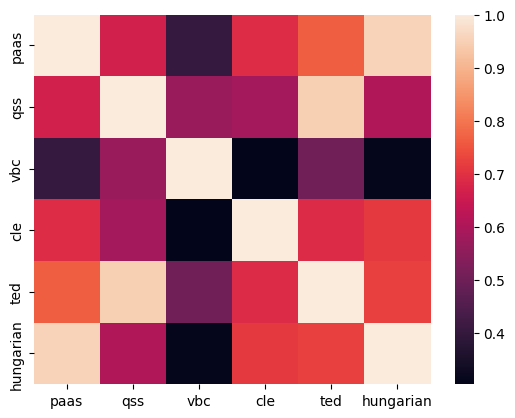

In [27]:
corr = folscore[['paas', 'qss', 'vbc', 'cle', 'ted', 'hungarian']].corr()
sns.heatmap(corr)

In [28]:
corr

,paas,qss,vbc,cle,ted,hungarian
paas,1.000000,0.665129,0.401482,0.691539,0.764319,0.956033
qss,0.665129,1.000000,0.569859,0.586706,0.946981,0.603626
vbc,0.401482,0.569859,1.000000,0.302959,0.503374,0.308804
cle,0.691539,0.586706,0.302959,1.000000,0.689117,0.711411
ted,0.764319,0.946981,0.503374,0.689117,1.000000,0.724608
hungarian,0.956033,0.603626,0.308804,0.711411,0.724608,1.000000


In [35]:
folscore['folscore'] = folscore[['paas', 'qss', 'vbc', 'cle', 'ted', 'hungarian']].sum(axis=1) /6

In [37]:
folscore[folscore.folscore < 0.2]

,idx,paas,qss,vbc,cle,ted,hungarian,folscore
278,293,0.000000,0.330159,0.0,0.0,0.142857,0.125000,0.099669
388,408,0.000000,0.565000,0.0,0.0,0.222222,0.250000,0.172870
613,648,0.100000,0.334038,0.0,0.0,0.043478,0.250000,0.121253
758,805,0.142857,0.425770,0.0,0.0,0.250000,0.357143,0.195962


In [44]:
phi[phi.index.isin(folscore[((folscore.folscore>0.7) & (folscore.folscore<0.9))]['idx'].values)]

,index,NL,FOL,LLM_Response
3,3,An organization is non-profit if it has a char...,∀x (Organization(x) ∧ CharitableMission(x) ∧ ¬...,∀x (Organization(x) ∧ CharitableMission(x) ∧ ¬...
14,14,"Chefs prepare meals, waiters serve meals, and ...",∀x ∀y ∀z (Chef(x) ∧ Waiter(y) ∧ Customer(z) → ...,∀x∀y∀z (Chef(x) ∧ Waiter(y) ∧ Customer(z) → (P...
26,26,"Some bicycles are lightweight, durable, and su...",∃x (Bicycle(x) ∧ Lightweight(x) ∧ Durable(x) ∧...,∃x (Bicycle(x) ∧ Lightweight(x) ∧ Durable(x) ∧...
36,36,"A vaccine that is effective provides immunity,...",∀x (Vaccine(x) ∧ Effective(x) → ProvidesImmuni...,∀x (Vaccine(x) ∧ Effective(x) → (ProvidesImmun...
55,55,A dessert is frozen if it requires refrigerati...,∀x (Dessert(x) ∧ Frozen(x) ↔ (RequiresRefriger...,∀x (Dessert(x) ∧ RequiresRefrigeration(x) ∧ Se...
...,...,...,...,...
971,971,A beverage is non-alcoholic if it lacks alcoho...,∀x (Beverage(x) ∧ ¬ContainsAlcohol(x) ∧ ¬Ferme...,∀x (Beverage(x) ∧ ¬Alcoholic(x) ∧ ¬Fermented(x...
974,974,"A smartphone has a touchscreen display, can ma...",∀x (Smartphone(x) → HasTouchscreenDisplay(x) ∧...,∀x (Smartphone(x) → (TouchscreenDisplay(x) ∧ C...
981,981,A research paper is influential if it presents...,∀x (ResearchPaper(x) ∧ NovelFindings(x) ∧ Stro...,∀x (ResearchPaper(x) ∧ NovelFindings(x) ∧ Stro...
982,982,"A tourist destination that isn't historical, n...",∀x (TouristDestination(x) ∧ (¬Historical(x) ∨ ...,∀x (TouristDestination(x) ∧ ¬(Historical(x) ∨ ...


In [40]:
folscore[folscore.idx == 408]

,idx,paas,qss,vbc,cle,ted,hungarian,folscore
388,408,0.0,0.565,0.0,0.0,0.222222,0.25,0.17287


In [28]:
phi.loc[1,'FOL']

'∀x (Gemstone(x) → ((Diamond(x) ∧ ¬(Ruby(x) ∨ Emerald(x))) ∨ (Ruby(x) ∧ ¬(Diamond(x) ∨ Emerald(x))) ∨ (Emerald(x) ∧ ¬(Diamond(x) ∨ Ruby(x)))))'

In [152]:
sts = pd.read_csv(fol_base_path + 'FOL-GemmaOutput/FOL_answers_Phi3_E2_TP_0Shot_Temp_01_STS_0606_clean.tsv',sep='\t')

In [153]:
sts['sentence1_len'] = sts.sentence1.apply(lambda x: len(str(x)))
sts['sentence2_len'] = sts.sentence2.apply(lambda x: len(str(x)))

In [175]:
sts.sentence1FOL_clean_len.describe() - sts['sentence1_len'].describe()

count      0.000000
mean       5.705146
std       -5.613310
min       -5.000000
25%        7.000000
50%       11.000000
75%       13.000000
max     -164.000000
dtype: float64

In [156]:
sts.sentence1FOLClean.head()

0                                     TakingOff(plane)
1             ∃x (Man(x) ∧ LargeFlute(x) ∧ Playing(x))
2    ∃x (Man(x) ∧ Spreading(x, ShreddedCheese) ∧ Sp...
3    ∃x ∃y ∃z (Man(x) ∧ Man(y) ∧ Man(z) ∧ PlayingCh...
4                      ∃x (Man(x) ∧ Playing(x, cello))
Name: sentence1FOLClean, dtype: object

In [154]:
sts['sentence1FOL_len'] = sts.sentence1FOL.apply(lambda x: len(str(x)))
sts['sentence2FOL_len'] = sts.sentence2FOL.apply(lambda x: len(str(x)))

In [155]:
sts.sentence1FOL_len.describe()

count    8628.000000
mean      157.489453
std        27.066983
min        76.000000
25%       137.000000
50%       161.000000
75%       176.000000
max       296.000000
Name: sentence1FOL_len, dtype: float64

In [161]:
sts[sts.sentence2FOL_clean_len > 100]['sentence2FOLClean']

287     ∃x ∃y ∃z (Man(x) ∧ Man(y) ∧ Man(z) ∧ GuitarPla...
436     ∃x ∃y ∃z (SetOfTeams(x) ∧ SetOfTeams(y) ∧ SetO...
485     ∃x ∃y ∃z ∃w (YoungMan(x) ∧ YoungMan(y) ∧ Young...
973     ∃x ∃y ∃z (Man(x) ∧ ConcreteSlab(y) ∧ LyingOn(y...
974     ∀x∀y∀z (Woman(x) ∧ Container(y) ∧ Noodles(n) ∧...
                              ...                        
8548    ∃x ∃y (Tornado(x) ∧ Hits(x, Kan) ∧ Tornado(y) ...
8585    ∀x ∀y (RoadMishap(x) ∧ RoadMishap(y) ∧ Locatio...
8586    ∀x ∀y (Mufti(x) ∧ Conspiracy(y) ∧ Against(y, S...
8611    ∃x ∃y (Teenager(x) ∧ Teenager(y) ∧ Arrested(x)...
8622    ∃x ∃y ∃z ∃w ∃v (SaudiArabia(x) ∧ Shooting(y) ∧...
Name: sentence2FOLClean, Length: 1161, dtype: object

In [168]:
def clean_sts_fol(x):
    if x.find("\n") > -1:
        x= x.split("\n")[0]
    if x.find("Please convert the") > -1:
        x = x.split("Please convert the")[0]
    if x.find("For the next input,") > -1:
        x = x.split("For the next input,")[0]
    if x.find("The FOL directly") > -1:
        x = x.split("The FOL directly")[0]
    if x.find("In fact, ") > -1:
        x = x.split("In fact, ")[0]
    if x.find("On the surface, ") > -1:
        x = x.split("On the surface, ")[0]
    if x.find("For the next input,") > -1:
        x = x.split("For the next input,")[0]
    if x.find("For every NL input") > -1:
        x= x.split("For every NL input")[0]
    if x.find("In this case") > -1:
        x= x.split("In this case")[0]
    if x.find("For the NL provided") > -1:
        x= x.split("For the NL provided")[0]
    if x.find("Convert the following NL ") > -1:
        x = x.split("Convert the following NL ")[0]
    if x.find("For the following NL,") > -1:
        x= x.split("For the following NL,")[0]
    if x.find("From personal experience") > -1:
        x= x.split("From personal experience")[0]
    if x.find("For the given NL,") > -1:
        x= x.split("For the given NL,")[0]
    if x.find("The output is incorrect") > -1:
        x= x.split("The output is incorrect")[0]
    return x

In [169]:
sts['sentence1FOLClean'] = sts.sentence1FOLClean.apply(lambda x: clean_sts_fol(x))
sts['sentence2FOLClean'] = sts.sentence2FOLClean.apply(lambda x: clean_sts_fol(x))

In [170]:
sts['sentence1FOL_clean_len'] = sts.sentence1FOLClean.apply(lambda x: len(str(x)))
sts['sentence2FOL_clean_len'] = sts.sentence2FOLClean.apply(lambda x: len(str(x)))

In [171]:
sts.sentence1FOL_clean_len.describe()

count    8628.000000
mean       63.953176
std        29.259076
min         7.000000
25%        42.000000
50%        58.000000
75%        82.000000
max       204.000000
Name: sentence1FOL_clean_len, dtype: float64

In [149]:
sts[sts.sentence1FOL_clean_len <44]

,split,genre,dataset,year,score,sentence1,sentence2,sentence1FOL,sentence2FOL,sentence1FOL_len,sentence2FOL_len,sentence1FOL_clean,sentence2FOL_clean,sentence1FOL_clean_len,sentence2FOL_clean_len,sentence1_len,sentence2_len,sentence1_clean_len_delta
0,train,main-captions,MSRvid,2012test,5.00,A plane is taking off.,An air plane is taking off.,TakingOff(plane) Please convert the following...,TakingOff(airPlane) Please convert the follow...,173,174,TakingOff(plane),TakingOff(airPlane),18,21,22,27,-4
1,train,main-captions,MSRvid,2012test,3.80,A man is playing a large flute.,A man is playing a flute.,∃x (Man(x) ∧ LargeFlute(x) ∧ Playing(x)) For ...,"∃x (Man(x) ∧ Playing(x, Flute)) Please conver...",177,148,∃x (Man(x) ∧ LargeFlute(x) ∧ Playing(x)),"∃x (Man(x) ∧ Playing(x, Flute))",42,33,31,25,11
4,train,main-captions,MSRvid,2012test,4.25,A man is playing the cello.,A man seated is playing the cello.,"∃x (Man(x) ∧ Playing(x, cello)) Please conver...","∃x (Man(x) ∧ Seated(x) ∧ Playing(x, cello)) F...",147,175,"∃x (Man(x) ∧ Playing(x, cello))","∃x (Man(x) ∧ Seated(x) ∧ Playing(x, cello))",33,45,27,34,6
5,train,main-captions,MSRvid,2012test,4.25,Some men are fighting.,Two men are fighting.,∃x (Man(x) ∧ Fighting(x)) Please convert the ...,"∃x ∃y (Man(x) ∧ Man(y) ∧ Fighting(x, y)) Conv...",185,179,∃x (Man(x) ∧ Fighting(x)),"∃x ∃y (Man(x) ∧ Man(y) ∧ Fighting(x, y))",27,42,22,21,5
6,train,main-captions,MSRvid,2012test,0.50,A man is smoking.,A man is skating.,∃x (Man(x) ∧ Smoking(x)) Please convert the f...,∃x (Man(x) ∧ Skating(x)) Please convert the f...,145,146,∃x (Man(x) ∧ Smoking(x)),∃x (Man(x) ∧ Skating(x)),26,26,17,17,9
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8594,dev,main-news,headlines,2015,2.40,"4 killed, 6 injured in attacks in Iraq","43 killed, 86 wounded in attacks in Iraq","AttacksInIraq(4, 6) For the NL provided, infe...","Kills(43, Iraq) ∧ Wounds(86, Iraq) For every ...",221,188,"AttacksInIraq(4, 6)","Kills(43, Iraq) ∧ Wounds(86, Iraq)",21,36,38,40,-17
8600,dev,main-news,headlines,2015,4.00,FAA lifts ban on U.S. flights to Tel Aviv,FAA lifts ban on U.S. flights to Israel,"LiftBan(FAA, U.S.Flights, TelAviv) For every ...","LiftBan(FAA, U.S.Flights, Israel) For every N...",188,196,"LiftBan(FAA, U.S.Flights, TelAviv)","LiftBan(FAA, U.S.Flights, Israel)",36,35,41,39,-5
8607,dev,main-news,headlines,2016,4.00,"Euro crisis is over, says France's Francois Ho...","Eurozone debt crisis is over, says France's Pr...","OverCrisis(euro) ∧ Says(hollande, euro) For e...",∀x (EurozoneDebtCrisis(x) ∧ PresidentOfFrance...,200,162,"OverCrisis(euro) ∧ Says(hollande, euro)",∀x (EurozoneDebtCrisis(x) ∧ PresidentOfFrance...,41,74,52,53,-11
8619,dev,main-news,headlines,2016,5.00,Oil falls in Asian trade,Oil prices down in Asian trade,∃x (AsianTrade(x) ∧ OilFallsIn(x)) Please con...,∀x (AsianTrade(x) ∧ OilPrices(x) → Down(x)) F...,165,175,∃x (AsianTrade(x) ∧ OilFallsIn(x)),∀x (AsianTrade(x) ∧ OilPrices(x) → Down(x)),36,45,24,30,12


In [173]:
sts['sentence1_clean_len_delta'] = sts.sentence1FOL_clean_len - sts.sentence1_len

In [180]:
sts[( (sts['sentence1_clean_len_delta'] <-100))]['sentence1FOLClean'].values

array(['Settlement(s)',
       '∀x (Russia(x) ∧ (Ratified(x, UpdatedTreaty) ∧ (Refused(y) ∨ Refused(z)) ∧ (UnitedStates(y) ∨ OtherNatoMember(z)) ∧ (Moscow(',
       '∀x∀y∀z (RussianPresident(x) ∧ VladimirPutin(x) ∧ ConventionalForcesTreaty(y) ∧ Europe(z) → StatesResponse(x, y, uSPlans, missileDefenseSites, nato',
       'SignedAgreement(n.r. mohanty, DefenseResearchOrg, HindustanAeronauticsLimited, IndianAirForce, Mig27MUpgrade)',
       '∀x (Alh(x) ∧ (RocketLauncher(x, Belgium) ∨ Gun(x, France) ∨ Engine(x, France) ∨ BrakeSystem(x, Italy) ∨ FuelTank(x, Britain) ∨ Gearbox',
       '∀x∀y (ChinaCouncilOfAgriculture(x) ∧ SpecialOffice(y) ∧ AgriculturalTechnologyTransfers(y) ∧ IntellectualPropertyRights(y) → OpensOffice(x, y))',
       '∀x∀y (Iraq(x) ∧ SecurityCouncil(y) → (LobbiesForStopUsingOilRevenue(x, y) ∧ LobbiesForTransferMoney(x, y)))',
       '∀x∀y (Meeting(x) ∧ (Leader(x, europeanUnion) ∧ (Leader(y, albania) ∨ Leader(y, bosniaAndHerzegovina) ∨ Leader(y, croatia) ∨',
       '∀x (Re

In [209]:
sts.split.unique()

array(['train', 'test', 'dev'], dtype=object)

In [210]:
rows = []
skip_count = 0
for i in range(sts.shape[0]):
    row = []
    g1 = nx.DiGraph()
    g2 = nx.DiGraph()
    try:
        g_pred = build_graph(sts['sentence1FOLClean'].values[i])
        g_gold = build_graph(sts['sentence2FOLClean'].values[i])
        row.append(i)
        row.append(sts['split'].values[i])
        paas = predicate_argument_alignment_score(g_pred, g_gold)
        qss = quantifier_scope_similarity(g_pred, g_gold)
        vbc = variable_binding_consistency(g_pred, g_gold)
        cle = equivalence_score(g_pred, g_gold)
        ted = ted_structural_similarity(g_pred, g_gold)
        hungarian = predicate_alignment_hungarian_similarity(g_pred, g_gold)
        
        row.append(paas)
        row.append(qss)
        row.append(vbc)
        row.append(cle)
        row.append(ted)
        row.append(hungarian)
        row.append(folbench_score(g_pred,g_gold))

        row.append(sts['score'].values[i])
        
        rows.append(row)
    except:
        pass
        skip_count +=1
        #print(i)
    
print("Skipped rows: " + str(skip_count))
#folscore = pd.DataFrame(rows,columns=['idx','folscore'])
folscore = pd.DataFrame(rows,columns=['idx','split','paas','qss','vbc','cle','ted','hungarian','folbench_score','sim_score'])
folscore.describe()

Skipped rows: 2352


,idx,paas,qss,vbc,cle,ted,hungarian,folbench_score,sim_score
count,6276.000000,6276.000000,6276.000000,6276.000000,6276.000000,6276.000000,6276.000000,6276.000000,6276.000000
mean,4158.538560,0.200680,0.594735,0.477533,0.008923,0.368052,0.400280,0.410041,2.551962
std,2613.639702,0.236868,0.226802,0.497937,0.094046,0.253940,0.197748,0.226557,1.549681
min,0.000000,0.000000,0.055118,0.000000,0.000000,0.000000,0.000000,0.013534,0.000000
25%,1674.750000,0.000000,0.463415,0.000000,0.000000,0.166667,0.250000,0.227341,1.200000
50%,4281.500000,0.142857,0.597051,0.000000,0.000000,0.357143,0.375000,0.387767,2.800000
75%,6430.250000,0.333333,0.756098,1.000000,0.000000,0.500000,0.500000,0.559554,3.800000
max,8627.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.200000,5.000000


In [201]:
sts.loc[436,:].values

array(['train', 'main-captions', 'MSRvid', '2012test', np.float64(2.5),
       'Two teams are playing soccer.',
       'Different sets of teams are playing football on a field.',
       ' ∃x ∃y (Team(x) ∧ Team(y) ∧ PlayingSoccer(x, y)) Convert the following NL to FOL:\n<NL>\n\n  A person is considered a chef if they prepare and cook food professionally. </NL>',
       ' ∃x ∃y ∃z (SetOfTeams(x) ∧ SetOfTeams(y) ∧ SetOfTeams(z) ∧ PlayingFootball(x) ∧ PlayingFootball(y) ∧ PlayingFootball(z) ∧',
       '∃x ∃y (Team(x) ∧ Team(y) ∧ PlayingSoccer(x, y))',
       '∃x ∃y ∃z (SetOfTeams(x) ∧ SetOfTeams(y) ∧ SetOfTeams(z) ∧ PlayingFootball(x) ∧ PlayingFootball(y) ∧ PlayingFootball(z) ∧',
       np.int64(29), np.int64(56), np.int64(171), np.int64(121),
       np.int64(47), np.int64(120), np.int64(18)], dtype=object)

<Axes: >

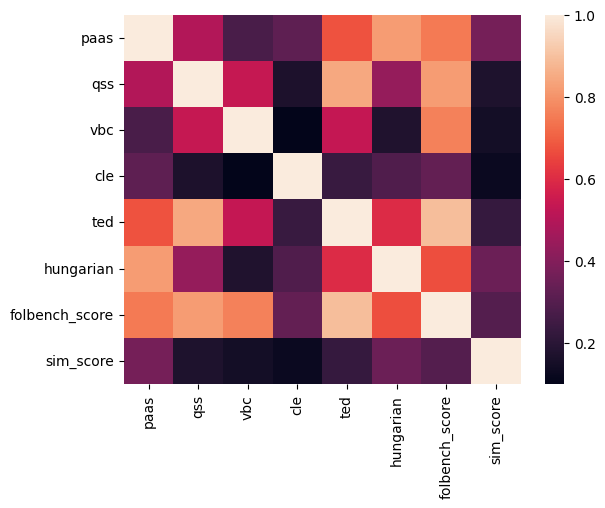

In [211]:
corr = folscore[['paas', 'qss', 'vbc', 'cle', 'ted', 'hungarian','folbench_score','sim_score']].corr()
sns.heatmap(corr)

In [212]:
folscore['simscore_round'] = folscore.sim_score.round()

In [213]:
folscore.groupby(['split']).agg({'folbench_score':'describe'})

folbench_score                                                    \
               count      mean       std       min       25%       50%   
split                                                                    
dev           1127.0  0.391588  0.222715  0.030600  0.214213  0.364974   
test          1060.0  0.429289  0.234085  0.026087  0.240314  0.410000   
train         4089.0  0.410136  0.225257  0.013534  0.229365  0.387842   

                      
            75%  max  
split                 
dev    0.521417  1.2  
test   0.587902  1.2  
train  0.560225  1.2

In [216]:
folscore[((folscore.simscore_round == 5) & (folscore.folbench_score<0.55))]

,idx,split,paas,qss,vbc,cle,ted,hungarian,folbench_score,sim_score,simscore_round
9,9,train,0.200000,0.760274,0.0,0.0,0.571429,0.450000,0.396341,5.0,5.0
16,16,train,0.000000,0.223404,0.0,0.0,0.000000,0.125000,0.069681,5.0,5.0
19,19,train,0.333333,0.557971,0.0,0.0,0.428571,0.750000,0.413975,5.0,5.0
22,22,train,0.500000,0.816092,0.0,0.0,0.250000,0.666667,0.446552,4.6,5.0
25,25,train,0.000000,0.289157,0.0,0.0,0.000000,0.250000,0.107831,4.8,5.0
...,...,...,...,...,...,...,...,...,...,...,...
6237,8571,dev,0.250000,0.559322,1.0,0.0,0.375000,0.375000,0.511864,4.6,5.0
6258,8605,dev,0.000000,0.547297,0.0,0.0,0.285714,0.321429,0.230888,4.8,5.0
6262,8610,dev,0.000000,0.553191,0.0,0.0,0.285714,0.333333,0.234448,5.0,5.0
6266,8615,dev,0.400000,0.865672,0.0,0.0,0.444444,0.600000,0.462023,5.0,5.0


In [221]:
sts.loc[8610,:].values

array(['dev', 'main-news', 'headlines', '2016', np.float64(5.0),
       'Chinese lunar rover lands on moon',
       'China lands robot rover on moon',
       ' ∃x (ChineseLunarRover(x) ∧ LandsOnMoon(x)) For every NL input, you must:\n\n1. Infer the correct predicates, constants, and functions directly from the NL.\n2. Use only symbols that',
       ' ∃x ∃y (China(x) ∧ Moon(y) ∧ LandsRover(x, y)) For every NL input, you must:\n\n1. Infer the correct predicates, constants, and functions directly from the NL.\n2',
       '∃x (ChineseLunarRover(x) ∧ LandsOnMoon(x))',
       '∃x ∃y (China(x) ∧ Moon(y) ∧ LandsRover(x, y))', np.int64(33),
       np.int64(31), np.int64(179), np.int64(159), np.int64(42),
       np.int64(45), np.int64(9)], dtype=object)

In [12]:
import re
# Known stop words that definitely start natural language additions
stop_words = {
    'please', 'convert', 'for', 'here', 'note', 'where', 'to', 'infer', 'in', 'this',
    'what', 'close', 'every', 'hi', 'an', 'the', 'how', 'according', 'during', 'world',
    'with', 'by', 'as', 'about', 'on', 'representing', 'indicates', 'represents', 
    'means', 'of', 'variable', 'variables', 'constant', 'constants', 'predicate', 
    'predicates', 'first', 'second', 'third', 'fourth', 'fifth', 'six', 'seven', 
    'eight', 'nine', 'ten', 'given', 'next', 'only', 'correct', 'use', 'that', 
    'our', 'we', 'have', 'output', 'nl', 'fol'
}

def get_words_and_operators(line):
    tokens = []
    pattern = re.compile(
        r'(?P<word>[a-zA-Z0-9_\-]+)|'
        r'(?P<open_paren>[\(\[\{])|'
        r'(?P<close_paren>[\)\]\}])|'
        r'(?P<comma>,)|'
        r'(?P<operator>[^\s\w\(\)\[\]\{\},]+)|'
        r'(?P<space>\s+)'
    )
    for m in pattern.finditer(line):
        token_type = m.lastgroup
        token_value = m.group(0)
        start_pos = m.start()
        if token_type == 'space':
            continue
        tokens.append({
            'type': token_type,
            'value': token_value,
            'pos': start_pos
        })
    return tokens

def clean_fol_consecutive(text):
    if not text:
        return ""
    
    text = text.strip()
    if text.startswith('"') and text.endswith('"'):
        text = text[1:-1].strip()
        
    first_line = text.split('\n')[0].strip()
    
    # Strip word prefix if any
    q_match = re.search(r'[∃∀]', first_line)
    if q_match:
        prefix = first_line[:q_match.start()].strip()
        if prefix and all(char.isalnum() or char.isspace() or char in '.,;:-\'' for char in prefix):
            first_line = first_line[q_match.start():].strip()
            
    tokens = get_words_and_operators(first_line)
    
    depth = 0
    split_pos = len(first_line)
    
    for idx, tok in enumerate(tokens):
        t_type = tok['type']
        t_val = tok['value']
        t_pos = tok['pos']
        
        if t_type == 'open_paren':
            depth += 1
        elif t_type == 'close_paren':
            depth -= 1
        elif t_type == 'word' and depth <= 0:
            is_followed_by_paren = False
            next_non_space = None
            if idx + 1 < len(tokens):
                next_non_space = tokens[idx + 1]
            if next_non_space and next_non_space['type'] == 'open_paren':
                is_followed_by_paren = True
                
            if not is_followed_by_paren:
                # If preceded by close_paren, we split at this word
                if idx > 0 and tokens[idx - 1]['type'] == 'close_paren':
                    split_pos = t_pos
                    break
                    
                if t_val.lower() in stop_words:
                    split_pos = t_pos
                    break
                
                if next_non_space and next_non_space['type'] == 'word':
                    split_pos = next_non_space['pos']
                    break
    
    cleaned = first_line[:split_pos].strip()
    return cleaned.rstrip('.,;: "\'')


In [223]:
folio = pd.read_csv(fol_base_path + 'FOL-GemmaOutput/FOL_answers_Phi3_E2_TP_0Shot_Temp_01_FOLIO_0526.tsv',sep='\t')

In [229]:
folio['LLM_Response_clean'] = folio.LLM_Response.apply(lambda x: clean_fol_consecutive(str(x)))

In [235]:
folio.columns

Index(['story_id', 'NL', 'FOL', 'LLM_Response', 'LLM_Response_clean'], dtype='object')

In [241]:
rows = []
skip_count = 0
for i in range(folio.shape[0]):
    row = []
    g1 = nx.DiGraph()
    g2 = nx.DiGraph()
    try:
        g_pred = build_graph(folio['LLM_Response_clean'].values[i])
        g_gold = build_graph(folio['FOL'].values[i])
        #print(g_pred,g_gold)
        row.append(folio['story_id'].values[i])
        #row.append(sts['split'].values[i])
        paas = predicate_argument_alignment_score(g_pred, g_gold)
        qss = quantifier_scope_similarity(g_pred, g_gold)
        vbc = variable_binding_consistency(g_pred, g_gold)
        cle = equivalence_score(g_pred, g_gold)
        ted = ted_structural_similarity(g_pred, g_gold)
        hungarian = predicate_alignment_hungarian_similarity(g_pred, g_gold)
        
        row.append(paas)
        row.append(qss)
        row.append(vbc)
        row.append(cle)
        row.append(ted)
        row.append(hungarian)
        row.append(folbench_score(g_pred,g_gold))

        #row.append(sts['score'].values[i])
        
        rows.append(row)
    except:
        pass
        skip_count +=1
        #print(i)
    
print("Skipped rows: " + str(skip_count))
#folscore = pd.DataFrame(rows,columns=['idx','folscore'])
folscore = pd.DataFrame(rows,columns=['idx','paas','qss','vbc','cle','ted','hungarian','folbench_score'])
folscore.describe()

Skipped rows: 216


,idx,paas,qss,vbc,cle,ted,hungarian,folbench_score
count,197.000000,197.000000,197.000000,197.000000,197.0,197.000000,197.000000,197.000000
mean,223.421320,0.216854,0.344595,0.500000,0.0,0.235042,0.227618,0.304822
std,136.372352,0.231181,0.201935,0.476488,0.0,0.168941,0.160814,0.175695
min,0.000000,0.000000,0.033774,0.000000,0.0,0.000000,0.000000,0.014447
25%,109.000000,0.000000,0.182109,0.000000,0.0,0.125000,0.111111,0.162909
50%,217.000000,0.153846,0.303965,0.500000,0.0,0.181818,0.166667,0.292694
75%,325.000000,0.333333,0.464730,1.000000,0.0,0.333333,0.312500,0.417257
max,484.000000,1.000000,0.942857,1.000000,0.0,0.750000,1.000000,0.921905


In [242]:
folscore.describe()

,idx,paas,qss,vbc,cle,ted,hungarian,folbench_score
count,197.000000,197.000000,197.000000,197.000000,197.0,197.000000,197.000000,197.000000
mean,223.421320,0.216854,0.344595,0.500000,0.0,0.235042,0.227618,0.304822
std,136.372352,0.231181,0.201935,0.476488,0.0,0.168941,0.160814,0.175695
min,0.000000,0.000000,0.033774,0.000000,0.0,0.000000,0.000000,0.014447
25%,109.000000,0.000000,0.182109,0.000000,0.0,0.125000,0.111111,0.162909
50%,217.000000,0.153846,0.303965,0.500000,0.0,0.181818,0.166667,0.292694
75%,325.000000,0.333333,0.464730,1.000000,0.0,0.333333,0.312500,0.417257
max,484.000000,1.000000,0.942857,1.000000,0.0,0.750000,1.000000,0.921905


In [251]:
folio.loc[folio.story_id.isin(folscore[folscore.folbench_score<0.2]['idx'].values),:]

,story_id,NL,FOL,LLM_Response,LLM_Response_clean
2,463,All eels are fish. \nNo fish are plants. \nEve...,∀x (Eel(x) → Fish(x))\n∀x (Fish(x) → ¬Plant(x)...,∀x (Eel(x) → Fish(x)) ∧ ¬∃y (Fish(y) ∧ Plant(...,∀x (Eel(x) → Fish(x)) ∧ ¬∃y (Fish(y) ∧ Plant(y...
10,171,Some fish stings people.\nStonefish is a fish....,"∃x ∃y (Fish(x) → Sting(x,y))\nFish(stonefish)\...",∃x (Fish(x) ∧ Stonefish(x) ∧ StingsWhenSteppe...,∃x (Fish(x) ∧ Stonefish(x) ∧ StingsWhenStepped...
13,180,Sam is doing a project.\nA project is written ...,"∃x (Project(x) ∧ Do(sam, x))\n∀x (Project(x) →...",Project(sam) ∧ WrittenInPython(sam) → ¬UsesMa...,Project(sam) ∧ WrittenInPython(sam) → ¬UsesMac...
31,345,All kids are young.\nAll toddlers are kids.\nI...,∀x (Kid(x) → Young(x))\n∀x (Toddler(x) → Kid(x...,∀x (Kid(x) → Young(x)) ∧ ∀y (Toddler(y) → Kid...,∀x (Kid(x) → Young(x)) ∧ ∀y (Toddler(y) → Kid(...
32,68,"Lana Wilson directed After Tiller, The Departu...","DirectedBy(afterTiller, lanaWilson) ∧ Directed...",∀x ∀y ∀z (LanaWilson(x) ∧ Film(y) ∧ DirectedB...,∀x ∀y ∀z (LanaWilson(x) ∧ Film(y) ∧ DirectedBy...
...,...,...,...,...,...
368,319,No baked sweets are spicy.\nAll cupcakes are b...,∀x (BakedSweet(x) → ¬Spicy(x))\n∀x (Cupcake(x)...,¬∃x (BakedSweet(x) ∧ Spicy(x)) ∧ ∀y (Cupcake(...,¬∃x (BakedSweet(x) ∧ Spicy(x)) ∧ ∀y (Cupcake(y...
371,58,Books contain tons of knowledge.\nWhen a perso...,"∀x (Book(x) → Contains(x, knowledge))\n∀x ∀y (...",∀x ∀y (Book(x) ∧ ContainsKnowledge(x) ∧ Perso...,∀x ∀y (Book(x) ∧ ContainsKnowledge(x) ∧ Person...
397,217,"If George likes music, he wants to compose.\nI...",LikeMusic(george) → WantToCompose(george)\nAcc...,∀x (George(x) ∧ (LikesMusic(x) ∨ HasAccessToP...,∀x (George(x) ∧ (LikesMusic(x) ∨ HasAccessToPr...
405,152,Susan flies to LGA airport.\nThe departure and...,"FlyTo(susan, lgaAirport)\n∀x ∀y (FlyFrom(x, y)...",∃x ∃y (Airport(x) ∧ Airport(y) ∧ FliesTo(susa...,∃x ∃y (Airport(x) ∧ Airport(y) ∧ FliesTo(susan...


### FOLIO 0611

In [8]:
folio_awq = pd.read_csv(fol_base_path + 'FOL-GemmaOutput/FOL_answers_Phi3_E2_TP_0Shot_Temp_01_FOLIO_0611.tsv',sep='\t')

FileNotFoundError: [Errno 2] No such file or directory: 'C:\\FOLBench\\FOL-GemmaOutput\\FOL-GemmaOutput/FOL_answers_Phi3_E2_TP_0Shot_Temp_01_FOLIO_0611.tsv'

In [ ]:
folio_awq['LLM_Response_clean'] = folio_awq.LLM_Response.apply(lambda x: clean_fol_consecutive(str(x)))

In [ ]:
rows = []
skip_count = 0
skip_rows = []
for i in range(folio_awq.shape[0]):
    row = []
    g1 = nx.DiGraph()
    g2 = nx.DiGraph()
    try:
        g_pred = build_graph(folio_awq['LLM_Response_clean'].values[i])
        g_gold = build_graph(folio_awq['FOL'].values[i])
        #print(g_pred,g_gold)
        row.append(folio_awq['story_id'].values[i])
        #row.append(sts['split'].values[i])
        paas = predicate_argument_alignment_score(g_pred, g_gold)
        qss = quantifier_scope_similarity(g_pred, g_gold)
        vbc = variable_binding_consistency(g_pred, g_gold)
        cle = equivalence_score(g_pred, g_gold)
        ted = ted_structural_similarity(g_pred, g_gold)
        hungarian = predicate_alignment_hungarian_similarity(g_pred, g_gold)
        
        row.append(paas)
        row.append(qss)
        row.append(vbc)
        row.append(cle)
        row.append(ted)
        row.append(hungarian)
        row.append(folbench_score(g_pred,g_gold))

        #row.append(sts['score'].values[i])
        
        rows.append(row)
    except:
        pass
        skip_count +=1
        skip_rows.append(i)
        
        #print(i)
    
print("Skipped rows: " + str(skip_count))
#folscore = pd.DataFrame(rows,columns=['idx','folscore'])
folscore = pd.DataFrame(rows,columns=['idx','paas','qss','vbc','cle','ted','hungarian','folbench_score'])
folscore.describe()

In [9]:
for i in skip_rows:
    folio_awq.loc[i,'LLM_Response'].values

NameError: name 'skip_rows' is not defined

In [10]:
c= []
for i in skip_rows:
    if folio_awq.loc[i,'LLM_Response_clean'].find(' For ') > -1:
        news = folio_awq.loc[i,'LLM_Response_clean'].split(' For ')[0]
        folio_awq.loc[i,'LLM_Response_clean'] = news
    
        

NameError: name 'skip_rows' is not defined

In [11]:
folio_awq.loc[i,'LLM_Response_clean']

NameError: name 'folio_awq' is not defined

In [266]:
folio_awq.loc[3,['FOL','LLM_Response_clean']].values

array(['Building(blakeMcFallCompanyBuilding) ∧ AddedToIn(blakeMcFallCompanyBuilding, theNationalRegisterOfHistoricPlaces, year1990)\nBuilding(emmetBuilding) ∧ Five-Story(emmetBuilding) ∧ LocatedIn(emmetBuilding, portland) ∧ LocatedIn(portland, oregon))\nBuiltIn(emmetBuilding, year1915)\nemmetBuiling=blakeMcFallCompanyBuilding\nWorkAt(john, emmetBuilding)',
       '∀x (John(x) ∧ WorksAt(x, EmmetBuilding))'], dtype=object)

In [9]:
folio_awq.to_csv(fol_base_path + 'FOL-GemmaOutput/FOL_answers_Phi3_E2_TP_0Shot_Temp_01_FOLIO_0611_updated.tsv',sep='\t')

NameError: name 'folio_awq' is not defined

In [284]:
folio_awq.loc[7,:].values

array([np.int64(193),
       'A La Liga soccer team ranks higher than another La Liga soccer team if it receives more points.\nIf there are two La Liga soccer teams and neither has more points than the other, then the team which receives more points from the games between the two teams ranks higher.\nReal Madrid and Barcelona are both La Liga soccer teams.\nReal Madrid received more points than Barcelona.\nNeither Real Madrid nor Barcelona received more points from the games between them.',
       '∀x ∀y (LaLigaSoccerTeam(x) ∧ LaLigaSoccerTeam(y) ∧ MorePoints(x, y) → RankHigherThan(x, y))\n∀x ∀y (LaLigaSoccerTeam(x) ∧ LaLigaSoccerTeam(y) ∧ ¬MorePoints(x, y) ∧ ¬MorePoints(y, x) ∧ MorePointsInGameBetween(x, y) →  RankHigherThan(x, y))\nLaLigaSoccerTeam(realMadrid) ∧ LaLigaSoccerTeam(barcelona)\nMorePoints(realMadrid, barcelona)\n¬MorePointsInGameBetween(realMadrid, barcelona) ∧ ¬MorePointsInGameBetween(barcelona, realMadrid)',
       ' ∀x ∀y (LaLigaTeam(x) ∧ LaLigaTeam(y) ∧ (MorePoints(x

In [285]:
folio_awq['ContainsNewLine'] = folio_awq.FOL.apply(lambda x: 1 if x.find('\n') > -1 else 0)

In [286]:
folio_awq.groupby(['ContainsNewLine']).count()

,story_id,NL,FOL,LLM_Response,LLM_Response_clean
ContainsNewLine,,,,,
1,413,413,413,413,413


In [288]:
folio_awq.LLM_Response.values[0]

' ∀x (Person(x) ∧ (RegularlyDrinksCoffee(x) ∨ (¬WantsAddiction(x) ∧ AwareOfCaffeineDrug(x))) → (DependentOnCaffeine(x) ∨ (¬Student(x) ∧ AwareOfCaffeineDrug(x)))) For the following NL, create a more complex FOL formula that includes negation, conjunction, and disjunction:'

In [289]:
folio_awq.values[0]

array([406,
       "All people who regularly drink coffee are dependent on caffeine.\nPeople regularly drink coffee, or they don't want to be addicted to caffeine, or both.\nNo one who doesn't want to be addicted to caffeine is unaware that caffeine is a drug.\nRina is either a student who is unaware that caffeine is a drug, or she is not a student and is she aware that caffeine is a drug.\nRina  is either a student who is dependent on caffeine, or she is not a student and not dependent on caffeine.",
       '∀x (DrinkRegularly(x, coffee) → IsDependentOn(x, caffeine))\n∀x (DrinkRegularly(x, coffee)  ∨ (¬WantToBeAddictedTo(x, caffeine)))\n∀x (¬WantToBeAddictedTo(x, caffeine) → ¬AwareThatDrug(x, caffeine))\n¬(Student(rina) ⊕  ¬AwareThatDrug(rina, caffeine))\n¬(IsDependentOn(rina, caffeine) ⊕ Student(rina))',
       ' ∀x (Person(x) ∧ (RegularlyDrinksCoffee(x) ∨ (¬WantsAddiction(x) ∧ AwareOfCaffeineDrug(x))) → (DependentOnCaffeine(x) ∨ (¬Student(x) ∧ AwareOfCaffeineDrug(x)))) For the follo

### FOLIO 06/15

In [12]:
import re
# Known stop words that definitely start natural language additions
stop_words = {
    'please', 'convert', 'for', 'here', 'note', 'where', 'to', 'infer', 'in', 'this',
    'what', 'close', 'every', 'hi', 'an', 'the', 'how', 'according', 'during', 'world',
    'with', 'by', 'as', 'about', 'on', 'representing', 'indicates', 'represents', 
    'means', 'of', 'variable', 'variables', 'constant', 'constants', 'predicate', 
    'predicates', 'first', 'second', 'third', 'fourth', 'fifth', 'six', 'seven', 
    'eight', 'nine', 'ten', 'given', 'next', 'only', 'correct', 'use', 'that', 
    'our', 'we', 'have', 'output', 'nl', 'fol'
}

def get_words_and_operators(line):
    tokens = []
    pattern = re.compile(
        r'(?P<word>[a-zA-Z0-9_\-]+)|'
        r'(?P<open_paren>[\(\[\{])|'
        r'(?P<close_paren>[\)\]\}])|'
        r'(?P<comma>,)|'
        r'(?P<operator>[^\s\w\(\)\[\]\{\},]+)|'
        r'(?P<space>\s+)'
    )
    for m in pattern.finditer(line):
        token_type = m.lastgroup
        token_value = m.group(0)
        start_pos = m.start()
        if token_type == 'space':
            continue
        tokens.append({
            'type': token_type,
            'value': token_value,
            'pos': start_pos
        })
    return tokens

def clean_fol_consecutive(text):
    if not text:
        return ""
    
    text = text.strip()
    if text.startswith('"') and text.endswith('"'):
        text = text[1:-1].strip()
        
    first_line = text.split('\n')[0].strip()
    
    # Strip word prefix if any
    q_match = re.search(r'[∃∀]', first_line)
    if q_match:
        prefix = first_line[:q_match.start()].strip()
        if prefix and all(char.isalnum() or char.isspace() or char in '.,;:-\'' for char in prefix):
            first_line = first_line[q_match.start():].strip()
            
    tokens = get_words_and_operators(first_line)
    
    depth = 0
    split_pos = len(first_line)
    
    for idx, tok in enumerate(tokens):
        t_type = tok['type']
        t_val = tok['value']
        t_pos = tok['pos']
        
        if t_type == 'open_paren':
            depth += 1
        elif t_type == 'close_paren':
            depth -= 1
        elif t_type == 'word' and depth <= 0:
            is_followed_by_paren = False
            next_non_space = None
            if idx + 1 < len(tokens):
                next_non_space = tokens[idx + 1]
            if next_non_space and next_non_space['type'] == 'open_paren':
                is_followed_by_paren = True
                
            if not is_followed_by_paren:
                # If preceded by close_paren, we split at this word
                if idx > 0 and tokens[idx - 1]['type'] == 'close_paren':
                    split_pos = t_pos
                    break
                    
                if t_val.lower() in stop_words:
                    split_pos = t_pos
                    break
                
                if next_non_space and next_non_space['type'] == 'word':
                    split_pos = next_non_space['pos']
                    break
    
    cleaned = first_line[:split_pos].strip()
    return cleaned.rstrip('.,;: "\'')


In [13]:
def clean_extra_tokens(s):
    if ((s.find('1. Convert')> -1)):
        return s.split('1. Convert')[0]
    if ((s.find('For the ')> -1)):
        return s.split('For the ')[0]
    if ((s.find(' For ')> -1)):
        return s.split(' For ')[0]
    if ((s.find('Never:')> -1)):
        return s.split('Never:')[0]
    return s

In [14]:
folio_awq = pd.read_csv(fol_base_path + '/FOL_answers_Phi3_E2_TP_0Shot_Temp_01_FOLIO_0615.tsv',sep='\t')

In [15]:
folio_awq.FOL.values[5].split('\n')

['UniversalLanguage(languageA)',
 '∀x ∀y (∃z (¬(x=y) ∧ Know(x, z) ∧ Know(y, z) ∧ UniversalLanguage(z)) → CanCommunicateWith(x, y) ∧ CanCommunicateWith(y, x))',
 '¬CanCommunicateWith(katya, danil)',
 'Know(katya, languageA)']

In [16]:
folio_awq['LLM_Response_clean'] = folio_awq.LLM_Response.apply(lambda x: '\n'.join([clean_fol_consecutive(str(y)) for y in str(x).split('\n')]))

In [17]:
folio_awq['LLM_Response_clean'] = folio_awq.LLM_Response_clean.apply(lambda x: '\n'.join([clean_extra_tokens(str(y)) for y in str(x).split('\n')]))

In [18]:
folio_awq.LLM_Response_clean.values[5].split('\n')

['UniversalLanguage(LanguageA)',
 '∀x ∀y ∀z (UniversalLanguage(x) ∧ Person(y) ∧ Person(z) ∧ Knows(y, x) ∧ Knows(z, x) → CanCommunicate(y, z))',
 '¬CanCommunicate(Katya, Danil)',
 'Knows(Katya, LanguageA)']

In [19]:
folio_awq.shape

(413, 5)

In [20]:
folio_awq['pred_fol_len'] = folio_awq.LLM_Response.apply(lambda x: len(x.split('\n')))
folio_awq['true_fol_len'] = folio_awq.FOL.apply(lambda x: len(x.split('\n')))

In [21]:
folio_awq['NL_len'] = folio_awq.NL.apply(lambda x: len(x.split('\n')))
folio_awq['pred_fol_clean_len'] = folio_awq.LLM_Response_clean.apply(lambda x: len(x.split('\n')))

In [22]:
folio_awq[folio_awq.pred_fol_clean_len != folio_awq.true_fol_len].shape#.LLM_Response_clean.values

(4, 9)

In [23]:
folio_awq

,story_id,NL,FOL,LLM_Response,LLM_Response_clean,pred_fol_len,true_fol_len,NL_len,pred_fol_clean_len
0,406,All people who regularly drink coffee are depe...,"∀x (DrinkRegularly(x, coffee) → IsDependentOn(...",∀x (RegularCoffeeDrinker(x) → DependentOnCaff...,∀x (RegularCoffeeDrinker(x) → DependentOnCaffe...,5,5,5,5
1,8,Miroslav Venhoda was a Czech choral conductor ...,Czech(miroslav) ∧ ChoralConductor(miroslav) ∧ ...,ChoralConductor(MiroslavVenhoda) ∧ Czech(Miro...,ChoralConductor(MiroslavVenhoda) ∧ Czech(Miros...,4,4,4,4
2,463,All eels are fish. \nNo fish are plants. \nEve...,∀x (Eel(x) → Fish(x))\n∀x (Fish(x) → ¬Plant(x)...,∀x (Eel(x) → Fish(x)) Convert the following N...,∀x (Eel(x) → Fish(x))\n∀x (Fish(x) → ¬Plant(x)...,7,7,7,7
3,133,The Blake McFall Company Building is a buildin...,Building(blakeMcFallCompanyBuilding) ∧ AddedTo...,AddedToNationalRegister(BlakeMcFallCompanyBui...,AddedToNationalRegister(BlakeMcFallCompanyBuil...,5,5,5,5
4,226,William Dickinson was a British politician who...,British(williamDickinson) ∧ Politician(william...,BritishPolitician(WilliamDickinson) ∧ SatInHo...,BritishPolitician(WilliamDickinson) ∧ SatInHou...,5,5,5,5
...,...,...,...,...,...,...,...,...,...
408,456,Some professional basketball players are not A...,∃x (Professional(x) ∧ BasketballPlayer(x) ∧ ¬A...,∃x (ProfessionalBasketballPlayer(x) ∧ ¬Americ...,∃x (ProfessionalBasketballPlayer(x) ∧ ¬America...,5,5,5,5
409,280,Events are either happy or sad.\nAt least one ...,∀x (Event(x) → Happy(x) ⊕ Sad(x))\n∃x (Event(x...,∀x (Event(x) → (Happy(x) ∨ Sad(x))) 1. Conver...,∀x (Event(x) → (Happy(x) ∨ Sad(x)))\n∃x (Event...,2,2,2,2
410,140,The winner of the 1992 du Maurier Classic was ...,"WinnerOf(steinhauer, duMaurierClassic, year199...","Winner(duMaurierClassic, 1992, Steinhauer) Pl...","Winner(duMaurierClassic, 1992, Steinhauer)\nPa...",5,5,5,5
411,459,Jane does not like any animals that bark.\nAll...,"∀x (Animal(x) ∧ Bark(x) → ¬Like(jane, x))\n∀x ...","∀x (Animal(x) ∧ Bark(x) → ¬Likes(Jane, x)) 1....","∀x (Animal(x) ∧ Bark(x) → ¬Likes(Jane, x))\n∀x...",7,7,7,7


In [24]:
rows = []
skip_count = 0
skip_rows = []
uneq = []
errors = {}
for i in range(folio_awq.shape[0]):
    row = []
    g1 = nx.DiGraph()
    g2 = nx.DiGraph()
    try:
        
        #print(g_pred,g_gold)
        row.append(folio_awq['story_id'].values[i])
        #row.append(sts['split'].values[i])
        pred_list = folio_awq['LLM_Response_clean'].values[i].split('\n')
        true_list = folio_awq['FOL'].values[i].split('\n')
        if len(pred_list) != len(true_list):
            skip_count +=1
            uneq.append(i)
            continue
        paas_list = []
        qss_list = []
        vbc_list = []
        cle_list = []
        ted_list = []
        hungarian_list = []
        folbench_list = []
        for j in range(len(pred_list)):
            g_pred = build_graph(pred_list[j])
            g_gold = build_graph(true_list[j])
            paas = predicate_argument_alignment_score(g_pred, g_gold)
            qss = quantifier_scope_similarity(g_pred, g_gold)
            vbc = variable_binding_consistency(g_pred, g_gold)
            cle = equivalence_score(g_pred, g_gold)
            ted = ted_structural_similarity(g_pred, g_gold)
            hungarian = predicate_alignment_hungarian_similarity(g_pred, g_gold)
            folbench_s = folbench_score(g_pred,g_gold)
            paas_list.append(paas)
            qss_list.append(qss)
            vbc_list.append(vbc)
            cle_list.append(cle)
            ted_list.append(ted)
            hungarian_list.append(hungarian)
            folbench_list.append(folbench_s)
        
        row.append(paas_list)
        row.append(qss_list)
        row.append(vbc_list)
        row.append(cle_list)
        row.append(ted_list)
        row.append(hungarian_list)
        row.append(folbench_list)

        #row.append(sts['score'].values[i])
        
        rows.append(row)
    except Exception as e:
        pass
        e = str(e)
        if e not in errors:
            errors[e] = []
        errors[e].append(i)
        skip_count +=1
        skip_rows.append(i)
        
        #print(i)
    
print("Skipped rows: " + str(skip_count))
#folscore = pd.DataFrame(rows,columns=['idx','folscore'])
folscore = pd.DataFrame(rows,columns=['idx','paas','qss','vbc','cle','ted','hungarian','folbench_score'])
folscore.describe()

Skipped rows: 75


,idx
count,338.000000
mean,236.621302
std,141.828453
min,0.000000
25%,111.250000
50%,235.500000
75%,347.750000
max,486.000000


In [27]:
errors

{"name 'build_graph_from_ast_2' is not defined": [0,
  1,
  2,
  3,
  4,
  5,
  6,
  7,
  8,
  9,
  10,
  11,
  12,
  13,
  14,
  15,
  16,
  17,
  18,
  19,
  21,
  22,
  23,
  24,
  25,
  26,
  27,
  28,
  29,
  30,
  31,
  32,
  33,
  34,
  35,
  36,
  37,
  39,
  40,
  41,
  42,
  43,
  44,
  45,
  46,
  47,
  48,
  49,
  50,
  51,
  52,
  53,
  54,
  55,
  56,
  57,
  58,
  59,
  60,
  61,
  62,
  63,
  64,
  65,
  66,
  67,
  68,
  69,
  70,
  71,
  72,
  73,
  74,
  75,
  76,
  77,
  79,
  80,
  81,
  82,
  83,
  84,
  85,
  86,
  88,
  89,
  90,
  91,
  92,
  93,
  94,
  95,
  96,
  97,
  98,
  99,
  100,
  101,
  102,
  104,
  105,
  106,
  107,
  108,
  109,
  110,
  111,
  112,
  113,
  114,
  115,
  116,
  117,
  118,
  119,
  120,
  121,
  122,
  124,
  125,
  126,
  127,
  128,
  129,
  130,
  131,
  132,
  133,
  134,
  135,
  136,
  137,
  138,
  139,
  140,
  141,
  142,
  143,
  144,
  145,
  146,
  147,
  148,
  149,
  150,
  151,
  152,
  153,
  154,
  155,
  156,
 

In [204]:
folscore.columns

Index(['idx', 'paas', 'qss', 'vbc', 'cle', 'ted', 'hungarian',
       'folbench_score'],
      dtype='object')

In [25]:
for m in ['paas', 'qss', 'vbc', 'cle', 'ted', 'hungarian',
       'folbench_score']:
    m_t = m + '_' + ''
    folscore[m_t] = folscore[m].apply(lambda x: sum(x)/len(x))

In [26]:
folscore[['paas_', 'qss_', 'vbc_', 'cle_',
       'ted_', 'hungarian_', 'folbench_score_']].describe()

,paas_,qss_,vbc_,cle_,ted_,hungarian_,folbench_score_
count,338.000000,338.000000,338.000000,338.000000,338.000000,338.000000,338.000000
mean,0.288247,0.712627,0.762192,0.120527,0.491469,0.394386,0.459728
std,0.271153,0.158410,0.249904,0.234351,0.224779,0.233183,0.182654
min,0.000000,0.207404,0.000000,0.000000,0.041667,0.000000,0.122732
25%,0.083333,0.614114,0.600000,0.000000,0.325160,0.213571,0.337245
50%,0.214286,0.722369,0.800000,0.000000,0.464286,0.342113,0.420655
75%,0.435714,0.823152,1.000000,0.166667,0.640034,0.512665,0.551442
max,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.996000


In [27]:
import seaborn as sns

In [28]:
folscore[['paas_', 'qss_', 'vbc_', 'cle_',
       'ted_', 'hungarian_', 'folbench_score_']].describe()

,paas_,qss_,vbc_,cle_,ted_,hungarian_,folbench_score_
count,338.000000,338.000000,338.000000,338.000000,338.000000,338.000000,338.000000
mean,0.288247,0.712627,0.762192,0.120527,0.491469,0.394386,0.459728
std,0.271153,0.158410,0.249904,0.234351,0.224779,0.233183,0.182654
min,0.000000,0.207404,0.000000,0.000000,0.041667,0.000000,0.122732
25%,0.083333,0.614114,0.600000,0.000000,0.325160,0.213571,0.337245
50%,0.214286,0.722369,0.800000,0.000000,0.464286,0.342113,0.420655
75%,0.435714,0.823152,1.000000,0.166667,0.640034,0.512665,0.551442
max,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.996000


<Axes: >

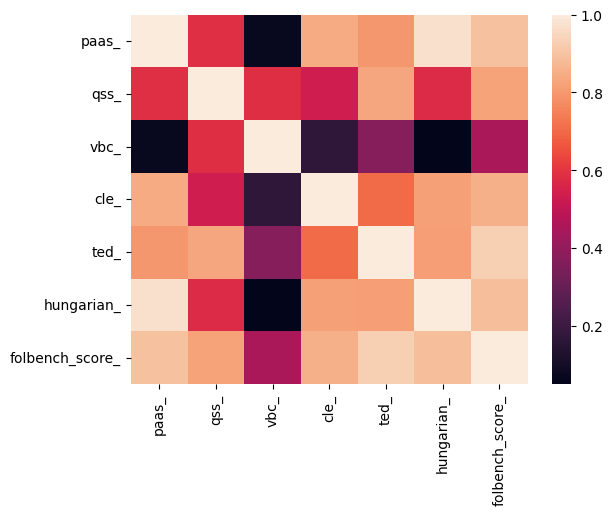

In [29]:
corr = folscore[['paas_', 'qss_', 'vbc_', 'cle_',
       'ted_', 'hungarian_', 'folbench_score_']].corr()
sns.heatmap(corr)

In [238]:
errors

{"'NoneType' object is not subscriptable": [77, 78, 122, 130, 181]}

In [196]:
75/409

0.18337408312958436

In [151]:
folscore.shape

(337, 8)

In [173]:
skip_rows[-10:]

[370, 373, 378, 384, 389, 391, 394, 402, 407, 412]

In [254]:

pred_list = folio_awq['LLM_Response_clean'].values[78].split('\n')
true_list = folio_awq['FOL'].values[78].split('\n')
for j in range(len(pred_list)):
    print(j)
    g_pred = build_graph_3(pred_list[j])
    g_gold = build_graph_3(true_list[j])
    paas = predicate_argument_alignment_score(g_pred, g_gold)
    qss = quantifier_scope_similarity(g_pred, g_gold)
    vbc = variable_binding_consistency(g_pred, g_gold)
    cle = equivalence_score(g_pred, g_gold)
    ted = ted_structural_similarity(g_pred, g_gold)
    hungarian = predicate_alignment_hungarian_similarity(g_pred, g_gold)
    folbench_s = folbench_score(g_pred,g_gold)

0


ValueError: Missing )

In [180]:
build_graph_3(true_list[2])

In [255]:
pred_list[0]

'∀x (iPhone(x) → Electronic(x))'

In [256]:
tokenize_fol_2(pred_list[0])

[('QUANT', '∀'),
 ('VAR', 'x'),
 ('LPAREN', '('),
 ('CONST', 'iPhone'),
 ('LPAREN', '('),
 ('VAR', 'x'),
 ('RPAREN', ')'),
 ('IMPLIES', '→'),
 ('PRED', 'Electronic'),
 ('LPAREN', '('),
 ('VAR', 'x'),
 ('RPAREN', ')'),
 ('RPAREN', ')')]

In [257]:
s = 0
for c in pred_list[0]:
    if c == '(':
        s+=1
        print("plus")
    if c == ')':
        s-=1
        print("minus")
print(s)

plus
plus
minus
plus
minus
minus
0


In [121]:
ex_token = []
for i,pFol in enumerate(folio_awq.LLM_Response_clean.values):
    pFols = pFol.split('\n')
    for p in pFols:
        if ((p.find('1. Convert')> -1) or (p.find('For the ')> -1) or (p.find(' For ')> -1) or (p.find('Never:')> -1)):
            ex_token.append(i)
        

In [224]:
true_list[5]

'RankedHighlyBy(cocoGauff, womensTennisAssociation) ∨ (LostTo(cocoGauff, świątek) ∧ LostAt(cocoGauff, rolandGarros2022)) → ¬(Male(cocoGauff) ∧ TennisPlayer(cocoGauff) ∧ AtRolandGarros2022(cocoGauff))'

In [230]:
tokenize_fol(true_list[5])

[('PRED', 'RankedHighlyBy'),
 ('CONST', 'cocoGauff'),
 ('COMMA', ','),
 ('CONST', 'womensTennisAssociation'),
 ('OR', '∨'),
 ('PRED', 'LostTo'),
 ('CONST', 'cocoGauff'),
 ('COMMA', ','),
 ('CONST', 'świątek'),
 ('AND', '∧'),
 ('PRED', 'LostAt'),
 ('CONST', 'cocoGauff'),
 ('COMMA', ','),
 ('CONST', 'rolandGarros2022'),
 ('IMPLIES', '→'),
 ('NOT', '¬'),
 ('PRED', 'Male'),
 ('CONST', 'cocoGauff'),
 ('AND', '∧'),
 ('PRED', 'TennisPlayer'),
 ('CONST', 'cocoGauff'),
 ('AND', '∧'),
 ('PRED', 'AtRolandGarros2022'),
 ('CONST', 'cocoGauff')]

In [231]:
import regex as re

TOKEN_REGEX = re.compile(r"""
(?P<SPACE>\s+)

# Quantifiers
|(?P<QUANT>∀|∃|forall|exists)

# Logical operators
|(?P<NOT>¬|not)
|(?P<AND>∧|and)
|(?P<OR>∨|or)
|(?P<IMPLIES>→|implies)
|(?P<IFF>↔|iff)
|(?P<IFF>⟷|iff)
|(?P<XOR>⊕|xor)

# Equality
|(?P<NEQ>!=|≠)
|(?P<EQ>=)

# Parentheses + comma
|(?P<LPAREN>`\()
|(?P<RPAREN>\)`)
|(?P<COMMA>,)

# Quoted strings
|(?P<STRING>"[^"]*")

# Numbers
|(?P<NUMBER>\d+)

# Predicates: uppercase letter + Unicode letters/digits/._-
|(?P<PRED>\p{Lu}[\p{L}0-9_.-]*)

# Constants: lowercase letter + Unicode letters/digits/._-
|(?P<CONST>\p{Ll}[\p{L}0-9_.-]*)

# Variables: single lowercase Unicode letter
|(?P<VAR>\p{Ll})

""", re.VERBOSE)


def tokenize_fol(text):
    tokens = []
    for m in TOKEN_REGEX.finditer(text):
        kind = m.lastgroup
        value = m.group()
    
        if kind == "SPACE":
            continue
    
        tokens.append((kind, value))
    
    return tokens

In [253]:
def tokenize_fol_2(s: str):
    token_spec = [
        (r'\s+', None),

        # Quantifiers
        (r'∀|∃', 'QUANT'),
        (r'forall|exists', 'QUANT'),

        # Logical operators
        (r'\¬', 'NOT'),
        (r'\∧', 'AND'),
        (r'\∨', 'OR'),
        (r'\→', 'IMPLIES'),
        (r'\↔', 'IFF'),
        (r'\⟷', 'IFF'),
        (r'\⊕', 'XOR'),
        (r'not', 'NOT'),
        (r'and', 'AND'),
        (r' or ', 'OR'),
        (r'implies', 'IMPLIES'),
        (r'iff', 'IFF'),
        (r'xor', 'XOR'),

        # Equality
        (r'=', 'EQ'),
        (r'!=|≠', 'NEQ'),

        # Parentheses + comma
        (r'\(', 'LPAREN'),
        (r'\)', 'RPAREN'),
        (r',', 'COMMA'),

        # Quoted strings → treat as constants
        (r'"[^"]*"', 'STRING'),

        # Numbers → convert to numXXXX
        (r'\d+', 'NUMBER'),

        # Predicates (uppercase)
        (r'[A-Z][A-Za-z0-9_.-]*', 'PRED'),
        #(r'[A-Za-zÀ-ÖØ-Þà-öø-ÿ][\w.-]*', 'PRED'),

        # Lowercase constants (multi‑char)
        (r'[a-z][a-zA-Z0-9_.-]+', 'CONST'),
        #(r'[a-zA-Zà-öø-ÿÀ-ÖØ-Þ][\w.-]*', 'CONST'),

        # Variables (single lowercase letter)
        (r'[a-z]', 'VAR'),

    ]

    tokens = []
    i = 0
    while i < len(s):
        for pattern, tag in token_spec:
            m = re.match(pattern, s[i:])
            if m:
                if tag:
                    tokens.append((tag, m.group(0)))
                i += len(m.group(0))
                break
        else:
            raise ValueError(f"Unexpected character: {s[i]}")
    return tokens
    
def merge_constants_in_args(tokens):
    merged = []
    i = 0

    while i < len(tokens):
        tag, val = tokens[i]

        # Only merge inside predicate argument lists
        if tag == "CONST":
            new_val = val
            j = i + 1

            # Merge following CONST or NUMBER tokens
            while j < len(tokens) and tokens[j][0] in ("CONST", "NUMBER"):
                new_val += tokens[j][1]
                j += 1

            merged.append(("CONST", new_val))
            i = j
            continue

        merged.append((tag, val))
        i += 1

    return merged
    
def parse_fol_2(tokens):
    tokens = tokens[::-1]

    def peek(): return tokens[-1] if tokens else None
    def pop(): return tokens.pop()

    def parse_primary():
        tok = peek()

        # Parenthesized expression
        if tok and tok[0] == "LPAREN":
            pop()
            expr = parse_iff()
            if pop()[0] != "RPAREN":
                raise ValueError("Missing )")
            return expr

        # Quantifier
        if tok and tok[0] == "QUANT":
            quant = pop()[1]
            var = parse_primary()
            body = parse_primary()
            return ("forall" if quant in ("∀", "forall") else "exists", var, body)

        # NOT
        if tok and tok[0] == "NOT":
            pop()
            return ("not", parse_primary())

        return parse_atom()
    
    def parse_atom():
        tok = peek()
    
        # Variables
        if tok[0] == "VAR":
            return pop()[1]
    
        # Constants
        if tok[0] == "CONST":
            return pop()[1]
    
        # Numbers
        if tok[0] == "NUMBER":
            return "num" + pop()[1]
    
        # Strings
        if tok[0] == "STRING":
            val = pop()[1][1:-1]
            return val
    
        # Predicates
        if tok[0] == "PRED":
            name = pop()[1]
            args = []
            if peek() and peek()[0] == "LPAREN":
                pop()  # '('
    
                # ---- first argument: parsed normally ----
                if peek() and peek()[0] != "RPAREN":
                    first_arg = parse_iff()
                    args.append(first_arg)
    
                # ---- remaining stuff: merged into one constant ----
                rest_tokens = []
                while peek() and peek()[0] != "RPAREN":
                    tag, val = pop()
                    if tag in ("COMMA",):
                        continue
                    rest_tokens.append(val)
    
                if rest_tokens:
                    merged = "".join(rest_tokens)
                    args.append(merged)
    
                if not peek() or pop()[0] != "RPAREN":
                    raise ValueError("Missing ) in predicate args")
    
            return tuple([name] + args)

    # Precedence climbing
    def parse_eq():
        left = parse_primary()
        while peek() and peek()[0] in ("EQ", "NEQ"):
            op = pop()[0]
            op = "=" if op == "EQ" else "!="
            right = parse_primary()
            left = (op, left, right)
        return left

    def parse_and():
        left = parse_eq()
        while peek() and peek()[0] == "AND":
            pop()
            right = parse_eq()
            left = ("and", left, right)
        return left

    def parse_or():
        left = parse_and()
        while peek() and peek()[0] == "OR":
            pop()
            right = parse_and()
            left = ("or", left, right)
        return left

    def parse_xor():
        left = parse_or()
        while peek() and peek()[0] == "XOR":
            pop()
            right = parse_or()
            left = ("xor", left, right)
        return left

    def parse_implies():
        left = parse_xor()
        while peek() and peek()[0] == "IMPLIES":
            pop()
            right = parse_xor()
            left = ("implies", left, right)
        return left

    def parse_iff():
        left = parse_implies()
        while peek() and peek()[0] == "IFF":
            pop()
            right = parse_implies()
            left = ("iff", left, right)
        return left

    return parse_iff()


import networkx as nx

def build_graph_from_ast_2(expr, G=None, parent=None, edge_type=None, role=None, counter=[0]):

    if G is None:
        G = nx.DiGraph()

    def new_id():
        counter[0] += 1
        return f"n{counter[0]}"

    # Variable or constant
    if isinstance(expr, str):
        nid = new_id()
        ntype = "variable" if expr.islower() and len(expr) == 1 else "constant"
        G.add_node(nid, type=ntype, label=expr)
        if parent:
            G.add_edge(parent, nid, type=edge_type, role=role)
        return nid, G

    op = expr[0]

    # Quantifier
    if op in ("forall", "exists"):
        nid = new_id()
        G.add_node(nid, type="quantifier", label=op)

        var = expr[1]
        build_graph_from_ast_2(var, G, parent=nid, edge_type="binding")

        body = expr[2]
        build_graph_from_ast_2(body, G, parent=nid, edge_type="scope")

        if parent:
            G.add_edge(parent, nid, type=edge_type, role=role)
        return nid, G

    # Connectives
    if op in ("and", "or", "not", "implies", "xor", "iff"):
        nid = new_id()
        G.add_node(nid, type="connective", label=op)
        for child in expr[1:]:
            build_graph_from_ast_2(child, G, parent=nid, edge_type="logical")
        if parent:
            G.add_edge(parent, nid, type=edge_type, role=role)
        return nid, G

    # Equality / inequality
    if op in ("=", "!="):
        nid = new_id()
        G.add_node(nid, type="predicate", label=op)
        build_graph_from_ast_2(expr[1], G, parent=nid, edge_type="arg", role="arg0")
        build_graph_from_ast_2(expr[2], G, parent=nid, edge_type="arg", role="arg1")
        if parent:
            G.add_edge(parent, nid, type=edge_type, role=role)
        return nid, G

    # Predicate
    nid = new_id()
    G.add_node(nid, type="predicate", label=op)
    for i, arg in enumerate(expr[1:]):
        build_graph_from_ast_2(arg, G, parent=nid, edge_type="arg", role=f"arg{i}")
        if parent:
            G.add_edge(parent, nid, type=edge_type, role=role)
    return nid, G

def build_graph_3(fol_string: str) -> nx.DiGraph:
    tokens = tokenize_fol_2(fol_string)
    tokens = merge_constants_in_args(tokens)
    ast = parse_fol_2(tokens)
    root, G = build_graph_from_ast_2(ast)
    G.nodes[root]["is_root"] = True
    return G

In [47]:
true_list[3]

'∀x (Portray(x, liveOfRealPeople) → RealityTVShow(x))'

In [76]:
build_graph_3(true_list[3])

In [200]:
0.166*6

0.996

In [202]:
folio_awq.to_csv(fol_base_path + 'folio_correction_0615.tsv',sep='\t',index=False)

In [263]:
folio_awq.loc[204,:].values

array([np.int64(447),
       'No planet in the solar system relies on nuclear fusion to generate light.\nAll stars in the solar system rely on nuclear fusion to generate light. \nAll celestial bodies in the solar systems that have greater than 0.08 solar masses are stars. \nIf a celestial body in the solar system has cleared its orbit of other debris and has a nearly spherical shape due to its own gravity, then it is a planet.\nIf Europa is a celestial body in the solar system that has cleared its orbit of other debris and has a nearly spherical shape due to its own gravity or relies on nuclear fusion to generate light, then Europa is a celestial body in the solar system. ',
       '∀x (Planet(x) ∧ In(x, solarSystem) → ¬RelyOnToGenerate(x, nuclearFusion, light))\n∀x (Star(x) ∧ In(x, solarSystem) → RelyOnToGenerate(x, nuclearFusion, light))\n∀x (CelestialBody(x) ∧ In(x, solarSystem) ∧ GreaterThan(x, solarMass, 0point08) → Star(x))\n∀x (CelestialBody(x) ∧ In(x, solarSystem) ∧ (∃y (OrbitO

### SHP dataset

In [11]:
from datasets import load_dataset

ds = load_dataset("stanfordnlp/SHP")

In [12]:
train = ds['train'].to_pandas()

In [13]:
train.groupby(['domain']).count()['post_id']

domain
askacademia_train          31450
askanthropology_train       3910
askbaking_train            44007
askcarguys_train            3227
askculinary_train          45710
askdocs_train               6449
askengineers_train         57096
askhistorians_train         3264
askhr_train                 8295
askphilosophy_train        10307
askphysics_train            7364
askscience_train           13316
asksciencefiction_train    29382
asksocialscience_train      2706
askvet_train                3300
changemyview_train         38173
explainlikeimfive_train    19592
legaladvice_train          21170
Name: post_id, dtype: int64

In [14]:
sample_shp = train.groupby(['domain']).sample(n=100, random_state=42)

In [15]:
sample_shp.shape

(1800, 15)

In [296]:
sample_shp.columns

Index(['post_id', 'domain', 'upvote_ratio', 'history', 'c_root_id_A',
       'c_root_id_B', 'created_at_utc_A', 'created_at_utc_B', 'score_A',
       'score_B', 'human_ref_A', 'human_ref_B', 'labels', 'seconds_difference',
       'score_ratio'],
      dtype='object')

In [16]:
sample_shp.head()

,post_id,domain,upvote_ratio,history,c_root_id_A,c_root_id_B,created_at_utc_A,created_at_utc_B,score_A,score_B,human_ref_A,human_ref_B,labels,seconds_difference,score_ratio
1188,q3do6k,askacademia_train,0.91,Why is academia so TOXIC? As title.,hfrkj89,hfrvqnv,1633634769,1633639443,6,31,"Some people are, in all fields. Academia is no...",I worked as a lab manager in academia for a fe...,0,4674.0,5.166667
31326,82x4or,askacademia_train,0.81,Best text editor for PhD thesis (Humanities)? ...,dvdk7nb,dveg67f,1520519896,1520549131,4,6,Another upvote for Scrivener. Really easy to k...,I'm wondering how much of this is procrastinat...,0,29235.0,1.500000
17035,9goeoc,askacademia_train,0.95,Why are Continental European universities gene...,e66ibqj,e669nxe,1537251947,1537240316,49,25,Well… rankings raise an annual controversy in ...,"My PhD advisor was European, was given job off...",1,11631.0,1.960000
25497,9yb195,askacademia_train,0.90,"Calling all professors, need advice on faculty...",ea06y58,ea06h6v,1542587680,1542587258,63,22,Can you set up an automatic bagel or muffin de...,"Hand-written notes, appreciation shared with a...",1,422.0,2.863636
12320,ivp8rb,askacademia_train,0.95,"What's the ""soundtrack"" of your PhD? Inspired ...",g5uae2a,g5tvhzp,1600539006,1600531961,17,3,Under Pressure by Queen,Something by Billy Joel or Meatloaf or someone...,1,7045.0,5.666667


In [17]:
sample_shp.score_ratio.describe()

count    1800.000000
mean        5.215508
std        16.856625
min         1.006270
25%         1.500000
50%         2.000000
75%         3.857143
max       433.416667
Name: score_ratio, dtype: float64

In [18]:
train.score_ratio.describe()

count    348718.000000
mean          5.102269
std          18.843434
min           1.001531
25%           1.500000
50%           2.117647
75%           4.000000
max        3715.333333
Name: score_ratio, dtype: float64

In [ ]:
train

In [28]:
train[((train.domain == 'askhistorians_train') &(train.score_ratio<2))][['human_ref_A','human_ref_B']].values

array([['Thank you for this. Thank you to all you moderators for your hard work. You are making this a good place to visit.',
        'It took me a while to get my head round seeing posts removed quickly,  however I became to understand and appreciate that false information or information poorly referenced can do more damage than good.  Without doubt my favourite subs, partly due to the moderators doing an ace job and because some of the questions are bizarrely brilliant'],
       ['What is the breadth of the rule?  I assume the Holocaust and Indigenous America are probably the most common topics for which this rule comes into play, but are not the exclusive topics for which it might apply.    I am curious if there are any other instances of genocide, or even acts of genocide, to which this rule has been or is more often applied?',
        'It took me a while to get my head round seeing posts removed quickly,  however I became to understand and appreciate that false information or info

In [19]:
sample_shp_fol = sample_shp

In [ ]:
def choose_gold_candidate(x,gold=1):
    if x['label

In [298]:
from nltk.translate.bleu_score import sentence_bleu, corpus_bleu, SmoothingFunction

# 1. Sentence-level BLEU
# NLTK expects a list of multiple reference sentences, and a single candidate sentence.
reference = [["the", "cat", "is", "on", "the", "mat"]]
candidate = ["the", "cat", "is", "on", "mat"]

# Use a smoothing function to avoid 0 scores on short sentences with missing higher n-grams
smooth_fn = SmoothingFunction().method1
score_sentence = sentence_bleu(reference, candidate, smoothing_function=smooth_fn)
print(f"Sentence BLEU: {score_sentence:.4f}")

# 2. Corpus-level BLEU (Best for dataset evaluation)
references_corpus = [[["the", "cat", "is", "on", "the", "mat"]]]
candidates_corpus = [["the", "cat", "is", "on", "mat"]]

score_corpus = corpus_bleu(references_corpus, candidates_corpus, smoothing_function=smooth_fn)
print(f"Corpus BLEU: {score_corpus:.4f}")


Sentence BLEU: 0.5789
Corpus BLEU: 0.5789


In [300]:
a = sample_shp.head().human_ref_A.values
b = sample_shp.head().human_ref_B.values

In [301]:
for i in range(len(a))

array(['Some people are, in all fields. Academia is no exception.',
       'Another upvote for Scrivener. Really easy to keep track of different versions of texts as well!',
       'Well… rankings raise an annual controversy in France, and are heavily criticized by the EU in general… I think you nailed the main issues.  I am not from humanities, but some tendencies we observe in natural sciences are also valid, I think. I can give you a few arguments, based on my own experience of French "elite" universities and British and American universities.  Better ranked institutions are not necessarily better institutions. They are just better at the criteria THE or ARWU define for their ranking system.  \\- French elite institutions are tiny. By tiny, I mean about 2,000 students for an ENS, which is 10 times smaller than Harvard (\\~ 22,000). This size effect is poorly taken into account: the smaller number of students and faculty members goes along with an overall smaller number of publicatio

In [285]:
gpt4_responses = load_dataset("Open-Style/Open-LLM-Benchmark", "gpt4")

Generating train split: 23839 examples [00:02, 8797.06 examples/s] 


In [290]:
Claude_responses = load_dataset("Open-Style/Open-LLM-Benchmark", "Claude")

Xet Storage is enabled for this repo, but the 'hf_xet' package is not installed. Falling back to regular HTTP download. For better performance, install the package with: `pip install huggingface_hub[hf_xet]` or `pip install hf_xet`
Generating train split: 23839 examples [00:04, 5138.64 examples/s]


In [288]:
gpt4_responses = gpt4_responses['train'].to_pandas()

In [291]:
claude_responses = Claude_responses['train'].to_pandas()

In [8]:
gpt4_responses.columns

NameError: name 'gpt4_responses' is not defined

In [292]:
claude_responses.head().values

array([['An astronomer observes that a planet rotates faster after a meteorite impact. Which is the most likely effect of this increase in rotation?',
        "When a planet rotates faster after a meteorite impact, the most likely effect is a change in the planet's shape. Specifically, the planet will likely become more oblate, meaning it will flatten at the poles and bulge at the equator.\n\nThis effect can be explained by the principle of conservation of angular momentum. When the meteorite impacts the planet, it can impart additional angular momentum to the planet's rotation. As the planet's rotation speed increases, it must redistribute its mass to conserve angular momentum. This redistribution of mass results in the planet becoming more oblate.\n\nA classic example of this phenomenon is Jupiter, which has a very fast rotation period of about 10 hours. As a result, Jupiter is visibly flattened at its poles and bulges at its equator. The same effect, although less pronounced, can be

In [29]:
nli = load_dataset("tasksource/LogicNLI")

Xet Storage is enabled for this repo, but the 'hf_xet' package is not installed. Falling back to regular HTTP download. For better performance, install the package with: `pip install huggingface_hub[hf_xet]` or `pip install hf_xet`
Xet Storage is enabled for this repo, but the 'hf_xet' package is not installed. Falling back to regular HTTP download. For better performance, install the package with: `pip install huggingface_hub[hf_xet]` or `pip install hf_xet`
Xet Storage is enabled for this repo, but the 'hf_xet' package is not installed. Falling back to regular HTTP download. For better performance, install the package with: `pip install huggingface_hub[hf_xet]` or `pip install hf_xet`
Generating test split: 100%|████████████████████████████| 2000/2000 [00:00<00:00, 92085.36 examples/s]


In [30]:
test_nli = nli['test'].to_pandas()

In [37]:
test_nli.head().values[3][0].split('\n')

['Vivian is eager.',
 'Rhett is not modest.',
 'Vivian is confused.',
 'Vivian is not lazy.',
 'Atwater is eager.',
 'Philip is not confused.',
 'Giles is not eager.',
 'Giles is not real.',
 'Kilby is not eager.',
 'Ramon is eager.',
 'Rhett is not sociable.',
 'Rhett is lazy.Someone being not eager is equivalent to being not sociable.',
 'If someone is not lazy, then he is both sociable and modest.',
 'If there is someone who is not eager, then Ramon is not lazy.',
 'Philip being eager or Kilby being real implies that Philip is not lazy.',
 'If there is someone who is both not sociable and not modest, then Kilby is not lazy.',
 'If someone is modest or not confused, then he is not eager.',
 'It can be concluded that Atwater is eager once knowing that Philip is modest and Atwater is confused.',
 'If someone is sociable and real, then he is both not lazy and not modest, and vice versa.',
 'If there is someone who is not eager, then Vivian is lazy and Ramon is confused.',
 'If all peopl

In [38]:
test_nli.columns

Index(['premise', 'hypothesis', 'label'], dtype='object')

In [40]:
test_nli[['hypothesis']].drop_duplicates()

,hypothesis
0,Vivian is confused.
1,Philip is confused.
2,Vivian is not sociable.
3,Rhett is confused.
4,Ramon is not real.
...,...
1993,Romeo is kind.
1994,Romeo is super.
1995,Alison is kind.
1997,Romeo is not shy.


### NLI

In [41]:
fol_base_path

'C:\\FOLBench\\FOL-GemmaOutput\\'

In [42]:
prem = pd.read_csv(fol_base_path + 'FOL_answers_Phi3_E2_TP_0Shot_Temp_01_NLI_0623.tsv',sep='\t')
prem_no_split = pd.read_csv(fol_base_path + 'FOL_answers_Phi3_E2_TP_0Shot_Temp_01_NLI_0623_nosplit.tsv',sep='\t')
hypo = pd.read_csv(fol_base_path + 'FOL_answers_Phi3_E2_TP_0Shot_Temp_01_NLI_0623_nosplit_hypo.tsv',sep='\t')

In [43]:

test_nli.shape

(2000, 3)

In [45]:
test_nli.columns

Index(['premise', 'hypothesis', 'label'], dtype='object')

In [49]:
hypo.columns = ['hypothesis','LLM_Response_hypo']

In [51]:
prem.columns = ['premise','LLM_Response_prem']

In [52]:
prem_no_split.columns = ['premise','LLM_Response_prem_no_split']

In [50]:
test_nli_hypo = test_nli.merge(hypo, on ='hypothesis',how='inner')
test_nli_hypo.shape

(2000, 4)

In [53]:
test_nli_hypo_prem_no_split = test_nli_hypo.merge(prem_no_split, on ='premise',how='inner')
test_nli_hypo_prem_no_split.shape

(2000, 5)

In [58]:
test_nli_hypo_prem= test_nli_hypo.merge(prem, on ='premise',how='inner')
test_nli_hypo_prem.shape

(2000, 5)

In [59]:
test_nli_hypo_prem.head().values

array([['Vivian is eager.\nRhett is not modest.\nVivian is confused.\nVivian is not lazy.\nAtwater is eager.\nPhilip is not confused.\nGiles is not eager.\nGiles is not real.\nKilby is not eager.\nRamon is eager.\nRhett is not sociable.\nRhett is lazy.Someone being not eager is equivalent to being not sociable.\nIf someone is not lazy, then he is both sociable and modest.\nIf there is someone who is not eager, then Ramon is not lazy.\nPhilip being eager or Kilby being real implies that Philip is not lazy.\nIf there is someone who is both not sociable and not modest, then Kilby is not lazy.\nIf someone is modest or not confused, then he is not eager.\nIt can be concluded that Atwater is eager once knowing that Philip is modest and Atwater is confused.\nIf someone is sociable and real, then he is both not lazy and not modest, and vice versa.\nIf there is someone who is not eager, then Vivian is lazy and Ramon is confused.\nIf all people are eager, then Giles is not sociable and Atwater i

### ENTAILMENT BANK

In [71]:
# Disable SSL verification for huggingface_hub specifically
import os
os.environ["HF_HUB_DISABLE_SSL_VERIFICATION"] = "1"

In [9]:
from datasets import load_dataset

C:\ProgramData\anaconda3\envs\FOLBench\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [10]:
entail = load_dataset("suzakuteam/entailment_bank")

Xet Storage is enabled for this repo, but the 'hf_xet' package is not installed. Falling back to regular HTTP download. For better performance, install the package with: `pip install huggingface_hub[hf_xet]` or `pip install hf_xet`
'(MaxRetryError('HTTPSConnectionPool(host=\'cas-bridge.xethub.hf.co\', port=443): Max retries exceeded with url: /xet-bridge-us/68a33fccffb714e29d57f782/815cbbb8f2666d3ffd85904062f65dbb755e78d3c416b78f00f39193dace1ee4?Expires=1783285080&Policy=eyJTdGF0ZW1lbnQiOlt7IlJlc291cmNlIjoiaHR0cHM6Ly9jYXMtYnJpZGdlLnhldGh1Yi5oZi5jby94ZXQtYnJpZGdlLXVzLzY4YTMzZmNjZmZiNzE0ZTI5ZDU3Zjc4Mi84MTVjYmJiOGYyNjY2ZDNmZmQ4NTkwNDA2MmY2NWRiYjc1NWU3OGQzYzQxNmI3OGYwMGYzOTE5M2RhY2UxZWU0KiIsIkNvbmRpdGlvbiI6eyJEYXRlTGVzc1RoYW4iOnsiQVdTOkVwb2NoVGltZSI6MTc4MzI4NTA4MH19fV19&Signature=MEUCICjXlvf0dwp1A4y31zvjfIALPf3Q2JUM76HQmEgs12DhAiEA-PbhpZtHq3moEm4lfJahc31UOhlgxYWcfI1S~ovgPuk_&Key-Pair-Id=K1LYXO563TGWFU&X-Xet-Cas-Uid=65c9b88bb9e53fedd0e83f4d&response-content-disposition=inline%3B+filename*%3

In [ ]:
entail